# Wiener filter vs. pseudo-inverse mapmaking

Two linear estimators of the sky from the same simulated drift-scan data:

* **Wiener filter**: the posterior mean under a Gaussian sky prior $S$.
  This is the pipeline's estimator.
* **Pseudo-inverse**: no prior. Take the SVD of the (noise-weighted) design
  matrix, invert it on the row space of $A$, and report the answer as
  $x^+$ **plus an arbitrary vector in the kernel** of $A$.

The data are the nine nominal beams of the `all-nominal` run (MARS, Nevada,
ALMA, Torres; no South Pole) at a single frequency over one sidereal day.
The design matrix is small enough to hold densely and to SVD exactly, so
nothing is limited by a randomized-SVD budget.

Everything after the SVD cell is interactive when `INTERACTIVE = True`
(first code cell). The sliders only rescale singular values or change
which modes are kept, so no SVD is redone. With `INTERACTIVE = False`
each panel is drawn once, as a static figure at the default slider
values, so the notebook runs top to bottom and exports cleanly.

## Notation

Data model: $y = Ax + n$ with $n \sim \mathcal N(0, N)$ and $N$ diagonal.
$x$ is the packed real alm vector of `mistsim.alm`. Write
$\tilde y = N^{-1/2} y$.

**Pseudo-inverse.** Let $A_w \equiv N^{-1/2}A = U\Sigma V^{\mathsf T}$.
$A_w$ has the same row space as $A$. Keeping the leading $r$ modes,

$$x^+_r = V_r \Sigma_r^{-1} U_r^{\mathsf T} \tilde y, \qquad
x = x^+_r + (I - V_r V_r^{\mathsf T})\, z, \quad z \text{ arbitrary}.$$

$x^+_r$ has noise covariance $V_r \Sigma_r^{-2} V_r^{\mathsf T}$, and
$1/\sigma_k$ is the noise on mode $k$ in kelvin. The kernel part is not
constrained at all. The packing preserves variance, so
$\lVert x \rVert^2 = \sum_{\ell m} |a_{\ell m}|^2 = \int T^2\, d\Omega$
(Parseval). $x^+$ is therefore the smallest-RMS sky consistent with the
data.

**Wiener filter.** Let
$\tilde A \equiv N^{-1/2} A S^{1/2} = \tilde U \tilde\Sigma \tilde V^{\mathsf T}$. Then

$$x_W = S^{1/2} \tilde V D\, \tilde U^{\mathsf T} \tilde y, \qquad
D_k = \frac{\tilde\sigma_k}{1 + \tilde\sigma_k^2},$$

with posterior covariance
$S^{1/2}\big[\tilde V (\tilde\Sigma^2 + I)^{-1} \tilde V^{\mathsf T}
+ (I - \tilde V \tilde V^{\mathsf T})\big] S^{1/2}$
(`docs/posterior_uncertainty.md`).

**How the two are related.**
* For a white prior $S = sI$, the Wiener filter in the $A_w$ basis is
  $\sigma_k / (\sigma_k^2 + 1/s)$. As $s \to \infty$ this becomes $x^+$ at
  full rank: the pseudo-inverse is a Wiener filter with an infinitely wide,
  white prior.
* With the real $C_\ell$ prior, $S \not\propto I$. Then $x_W$ lies in
  $S \cdot \mathrm{row}(A)$, not in $\mathrm{row}(A)$: the prior *chooses* the
  kernel vector, where the pseudo-inverse sets it to zero.
* As $\alpha \to \infty$ (below), $x_W \to S^{1/2} \tilde A^+ \tilde y$. That
  is the minimum-$S^{-1}$-norm solution: a pseudo-inverse in the prior's
  metric instead of the Euclidean one.

**Tuning knobs (sliders).**
* Pseudo-inverse rank $r$. This is equivalent to a noise cut $1/\sigma_r$ in K.
* Wiener prior amplitude $\alpha$: $S \to \alpha S$, so
  $\tilde\sigma \to \sqrt\alpha\, \tilde\sigma$.
* Noise scale $\beta$: $N \to \beta N$, so every $\sigma \to \sigma/\sqrt\beta$.
  The noise realization is scaled by $\sqrt\beta$.

In [1]:
import os

# True: ipympl figures with sliders. False: static inline figures at the
# default slider values, for running all cells or exporting.
INTERACTIVE = False

# Enable 64-bit JAX before croissant/mistsim import JAX.
os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("JAX_ENABLE_X64", "True")

'True'

In [2]:
import hashlib
import time
from functools import lru_cache
from pathlib import Path

import healpy as hp
import ipywidgets as widgets
import jax
import jax.numpy as jnp
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as sla
from IPython import get_ipython
from IPython.display import HTML, display

import mistsim.mapmaking as mm
import mistsim.pipeline as mspipe
import mistsim.plotting as msplt
from mistsim.alm import packed_lm_indices

assert jax.config.jax_enable_x64, "restart the kernel: JAX is not 64-bit"

get_ipython().run_line_magic(
    "matplotlib", "widget" if INTERACTIVE else "inline"
)

## 1. Configuration

`DATA_LMAX` sets only the resolution of the forward simulation. The inverse
is always at `LMAX`.

* `DATA_LMAX = LMAX` (default): the data are $A x_{\rm true} + n$, with the
  same $A$ that is inverted. There is no model error, so the two methods
  differ only by the prior.
* `DATA_LMAX = 179`: the nominal pipeline (`lmax_sim` in `runs.yaml`). Sky
  power at $\ell >$ `LMAX` is in the data but not in $A$, an unmodelled
  systematic. The first run is slower (beam transforms at 179); later runs
  load from the cache.

In [3]:
CONFIG = Path("configs/runs.yaml")
RUN = "all-nominal"  # the 9 nominal beams: MARS, NV, ALMA, Torres
BEAMS = None  # None = all beams of RUN, or a subset of them
FREQ_MHZ = 40
LMAX = 90  # inverse (mapmaking) resolution
DATA_LMAX = LMAX  # forward-sim resolution; 179 = nominal pipeline
N_TIMES = None  # None = Nyquist, 2 DATA_LMAX + 1 per sidereal day

RCOND = 1e-12  # modes with sigma <= RCOND * sigma_max are zero
PICARD_WINDOW = 51  # modes per running mean, data-only Picard plot
NSIDE_MAP = 32  # resolution of the interactive maps
PLOT_LMAX = 10  # low-pass for the large-scale maps
GALACTIC = True  # show maps in galactic coordinates
N_KERNEL_DRAWS = 3  # prior draws z in the family x+ + (I - P) z
SEED = 2718

CACHE_DIR = Path("results/wiener_vs_pinv")
RECOMPUTE = False  # True = ignore the cached simulation and SVDs

In [4]:
cfg = mspipe.load_config(CONFIG, RUN)
if BEAMS is not None:
    missing = set(BEAMS) - {s["name"] for s in cfg["sites"]}
    if missing:
        raise ValueError(f"not beams of {RUN}: {sorted(missing)}")
    cfg["sites"] = [s for s in cfg["sites"] if s["name"] in BEAMS]
cfg["sky"]["freqs"] = [FREQ_MHZ]
obs = cfg["observation"]
obs["lmax"] = LMAX
obs["lmax_sim"] = DATA_LMAX
if N_TIMES is not None:
    obs["n_times"] = N_TIMES

beam_names = [s["name"] for s in cfg["sites"]]
n_beams = len(beam_names)
n_times = mspipe.resolve_n_times(obs)
ndata = n_beams * n_times
nalm = (LMAX + 1) ** 2
ell_p, m_p = packed_lm_indices(LMAX)
mode_ceiling = 2 * LMAX + 1  # max rank one beam can add (see section 3)
# max rank of the stack at each m >= 0, in packed real dimensions: column m
# of the (ell, m) triangle holds LMAX + 1 - m modes, one number per beam
m_ceiling = np.array(
    [min(n_beams, LMAX + 1 - m) * (2 if m else 1) for m in range(LMAX + 1)]
)

beams_id = hashlib.sha1(",".join(beam_names).encode()).hexdigest()[:8]
tag = f"{FREQ_MHZ}mhz_lmax{LMAX}_data{DATA_LMAX}_nt{n_times}_{beams_id}"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print(f"{n_beams} beams at {FREQ_MHZ} MHz:")
for s in cfg["sites"]:
    print(f"  {s['name']:22s} lat {s['lat']:+7.2f}")
print(f"A: {ndata} x {nalm} ({ndata * nalm * 8 / 1e9:.2f} GB)")
print(f"data simulated at lmax {DATA_LMAX}, inverted at lmax {LMAX}")

9 beams at 40 MHz:
  mars-csa2022-dip       lat  +79.42
  mars-mono-analytic     lat  +79.42
  nv-dip                 lat  +37.21
  nv-mono-analytic       lat  +37.21
  mars-lake-dip          lat  +79.42
  alma-csa2022-dip       lat  -23.03
  alma-mono-analytic     lat  -23.03
  torres-csa2022-dip     lat  -50.00
  torres-mono-analytic   lat  -50.00
A: 4500 x 8281 (0.30 GB)
data simulated at lmax 90, inverted at lmax 90


### Helpers

Maps, norms and plotting utilities shared by all the panels.

* Every sky vector is a packed real alm. Norms are turned into a sky RMS in
  kelvin with Parseval, $T_{\rm rms} = \sqrt{\lVert x \rVert^2 / 4\pi}$.
* The interactive maps are drawn from precomputed Mollweide pixel lookups,
  so an update is a matrix-vector product plus an image refresh.

In [5]:
C_TRUE = "#0b0b0b"  # truth
C_WIENER = "#2a78d6"  # Wiener filter
C_PINV = "#eb6834"  # pseudo-inverse
C_ROW = "#1baf7a"  # noiseless pseudo-inverse P_r x_true
C_MUTED = "#8a8985"

L1 = LMAX + 1
N_HP = L1 * (L1 + 1) // 2
NPIX = hp.nside2npix(NSIDE_MAP)
SCOPES = {"large": ell_p <= PLOT_LMAX, "full": np.ones(nalm, dtype=bool)}
SCOPE_LABEL = {"large": f"ℓ ≤ {PLOT_LMAX}", "full": f"ℓ ≤ {LMAX}"}


def packed_to_hp(X):
    """Packed real alm rows (k, nalm) -> healpy complex alm (k, N_HP)."""
    X = np.atleast_2d(X)
    pos = (X[:, L1:N_HP] + 1j * X[:, N_HP:]) / np.sqrt(2)
    return np.concatenate([X[:, :L1] + 0j, pos], axis=1)


def maps_of(X, scope):
    """HEALPix maps (k, NPIX) of packed alm rows, restricted to scope."""
    alms = packed_to_hp(np.atleast_2d(X) * SCOPES[scope])
    return np.array([hp.alm2map(a, NSIDE_MAP, lmax=LMAX) for a in alms])


def rms(sq_norm):
    """Sky RMS [K] from a squared packed-alm norm (Parseval)."""
    return np.sqrt(np.asarray(sq_norm) / (4 * np.pi))


def cl_packed(x, y=None):
    """C_ell (or the cross C_ell) of packed alm; equals hp.alm2cl."""
    y = x if y is None else y
    ells = np.arange(L1)
    return np.bincount(ell_p, weights=x * y, minlength=L1) / (2 * ells + 1)


LM_COUNT = np.zeros((L1, L1))
np.add.at(LM_COUNT, (ell_p, m_p), 1)


def lm_image(v):
    """Packed vector -> (ell, m) image, averaging the re/im entries."""
    img = np.zeros((L1, L1))
    np.add.at(img, (ell_p, m_p), v)
    return np.ma.masked_where(LM_COUNT == 0, img / np.maximum(LM_COUNT, 1))


class Moll:
    """Mollweide pixel lookup for fast in-place map updates."""

    def __init__(self, nside, xsize=360, galactic=GALACTIC):
        # maps are equatorial ("C"); healpy rotates only when projmap
        # is told the input frame and the projector the output frame
        frame_in, frame_out = ("C", "G") if galactic else (None, None)
        self.proj = hp.projector.MollweideProj(xsize=xsize, coord=frame_out)
        idx = self.proj.projmap(
            np.arange(hp.nside2npix(nside), dtype=float),
            lambda x, y, z: hp.vec2pix(nside, x, y, z),
            coord=frame_in,
        )
        self.outside = ~np.isfinite(idx)
        self.idx = np.where(self.outside, 0, idx).astype(int)
        self.extent = self.proj.get_extent()

    def image(self, m):
        return np.ma.masked_array(m[self.idx], self.outside)


MOLL = Moll(NSIDE_MAP)
MOLL_EQ = Moll(NSIDE_MAP, galactic=False)  # for maps read against dec


def moll_image(ax, title, cmap="viridis", moll=MOLL):
    im = ax.imshow(
        moll.image(np.zeros(NPIX)),
        origin="lower",
        extent=moll.extent,
        cmap=cmap,
        interpolation="nearest",
    )
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
    cb = ax.figure.colorbar(
        im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.02
    )
    cb.ax.tick_params(labelsize=8)
    return im


def set_map(im, m, lim=None, symmetric=False, moll=MOLL):
    if symmetric:
        v = np.max(np.abs(m)) if lim is None else lim
        lim = (-v, v)
    elif lim is None:
        lim = (m.min(), m.max())
    im.set_data(moll.image(m))
    im.set_clim(*lim)


def graticule(ax, moll=MOLL_EQ, decs=(-60, -30, 0, 30, 60)):
    """Lines of constant declination on an equatorial Mollweide image."""
    ra = np.linspace(-180, 180, 181)
    for dec in decs:
        x, y = moll.proj.ang2xy(ra, np.full_like(ra, dec), lonlat=True)
        ax.plot(x, y, color=C_MUTED, lw=0.5, scalex=False, scaley=False)


def frac_rms(m_hat, m_true):
    """RMS over pixels of the fractional residual (m_hat - m) / m."""
    return np.sqrt(np.mean(((m_hat - m_true) / m_true) ** 2))


def html_table(rows):
    """{row label: {column: formatted value}} -> an HTML table."""
    cols = list(next(iter(rows.values())))
    pad = "padding: 1px 10px"
    head = "".join(f"<th style='{pad}'>{c}</th>" for c in cols)
    body = "".join(
        f"<tr><td style='{pad}'>{name}</td>"
        + "".join(
            f"<td style='{pad}; text-align: right'>{v}</td>"
            for v in row.values()
        )
        + "</tr>"
        for name, row in rows.items()
    )
    return f"<table><tr><th></th>{head}</tr>{body}</table>"


def connect(update, controls):
    """Run update now and on every control change; errors show below.

    Without INTERACTIVE, run it once and let errors raise.
    """
    out = widgets.Output()
    if not INTERACTIVE:
        update()
        return out

    def run(_=None):
        with out:
            out.clear_output()
            update()

    for ctrl in controls:
        ctrl.observe(run, names="value")
    run()
    return out


def show_panel(*items):
    """Display figures and widgets as one panel.

    Without INTERACTIVE: each figure as a static image, closed afterwards
    so that plt.show() in a later cell does not draw it again; HTML
    widgets as HTML; no controls.
    """
    if INTERACTIVE:
        display(
            widgets.VBox(
                [i.canvas if isinstance(i, plt.Figure) else i for i in items]
            )
        )
        return
    for item in items:
        if isinstance(item, plt.Figure):
            display(item)
            plt.close(item)
        elif isinstance(item, widgets.HTML):
            display(HTML(item.value))

## 2. Simulated data and the dense design matrix

The forward model uses the pipeline's own functions: `setup_sky_multi_freq`,
`simulate_waterfall` and `_prepare_freq_data`. Noise and the $C_\ell$ prior
come from `compute_noise` and `compute_prior`, as in the nominal runs.

$A$ is built column by column by pushing unit vectors through the same
forward operator, `mapmaking._forward_single_freq`, so it is exactly the
pipeline's operator. Its shape is $n_{\rm beams} n_{\rm times} \times
(\ell_{\max}+1)^2$.

Results are cached under `CACHE_DIR`, which is gitignored as `*.npz`. The
first run takes a few minutes, mostly for the beam transforms.

In [6]:
def dense_block(beam_alm, phases, chunk=256):
    """Dense A for one beam: the forward model applied to unit vectors."""
    n = beam_alm.shape[0] ** 2
    fwd = jax.jit(jax.vmap(mm._forward_single_freq, in_axes=(0, None, None)))
    cols = []
    for start in range(0, n, chunk):
        idx = np.arange(start, min(start + chunk, n))
        unit = np.zeros((idx.size, n))
        unit[np.arange(idx.size), idx] = 1.0
        cols.append(np.asarray(fwd(jnp.asarray(unit), beam_alm, phases)))
    return np.concatenate(cols).T


def simulate(cfg):
    sky_data = mspipe.setup_sky_multi_freq(cfg)
    wfs = [mspipe.simulate_waterfall(s, sky_data) for s in cfg["sites"]]
    fdata = mspipe._prepare_freq_data(
        cfg,
        sky_data["times"],
        sky_data["sim_freqs"],
        y=np.concatenate([w["y"] for w in wfs], axis=1),
        x_packed=sky_data["x_packed"],
        x_hp=sky_data["x_hp"],
        beam_alms_eq=[w["beam_alm_eq"] for w in wfs],
    )
    A = np.concatenate(
        [
            dense_block(fdata["beam_alms"][0, i], fdata["phases"][i])
            for i in range(len(cfg["sites"]))
        ]
    )
    return {
        "A": A,
        "y": np.asarray(fdata["y"][0]),
        "noise": np.asarray(fdata["noise"][0]),
        "Ndiag": np.asarray(fdata["Ndiag"][0]),
        "Sdiag": np.asarray(fdata["Sdiag"][0]),
        "x_true": np.asarray(fdata["x_packed"][0]),
    }


data_path = CACHE_DIR / f"{tag}_data.npz"
if data_path.exists() and not RECOMPUTE:
    data = dict(np.load(data_path))
    print(f"loaded {data_path}")
else:
    t0 = time.time()
    data = simulate(cfg)
    np.savez(data_path, **data)
    print(f"simulated in {time.time() - t0:.0f} s -> {data_path}")

A, y, noise = data["A"], data["y"], data["noise"]
Ndiag, Sdiag, x_true = data["Ndiag"], data["Sdiag"], data["x_true"]
assert A.shape == (ndata, nalm)

loaded results/wiener_vs_pinv/40mhz_lmax90_data90_nt500_bddedd45_data.npz


In [7]:
resid_model = y - A @ x_true
print(f"A: {A.shape}, {A.nbytes / 1e9:.2f} GB")
print(
    f"|y - A x_true| / |y| = "
    f"{np.linalg.norm(resid_model) / np.linalg.norm(y):.2e}"
)
print(
    f"model-error chi^2 / N_data = "
    f"{np.sum(resid_model**2 / Ndiag) / ndata:.3e}  (noise alone: 1)"
)
print(
    f"noise per sample: {np.sqrt(Ndiag).min():.3f}"
    f" - {np.sqrt(Ndiag).max():.3f} K"
)

A: (4500, 8281), 0.30 GB
|y - A x_true| / |y| = 2.07e-15
model-error chi^2 / N_data = 8.013e-22  (noise alone: 1)
noise per sample: 0.313 - 1.761 K


## 3. The two SVDs

Both are exact dense SVDs (`numpy.linalg.svd`):

* $A_w = N^{-1/2} A$ for the pseudo-inverse. $\sigma_k$ is in K$^{-1}$, and
  $1/\sigma_k$ is the noise on mode $k$.
* $\tilde A = N^{-1/2} A S^{1/2}$ for the Wiener filter. $\tilde\sigma_k$ is a
  signal-to-noise ratio in units of the prior.

Modes with $\sigma \le$ `RCOND` $\sigma_{\max}$ are numerically zero and are
dropped. The complement of the kept modes is the kernel.

**Why each beam adds at most $2\ell_{\max}+1$ modes.** Earth rotation is a
rotation about the equatorial $z$ axis. One beam's timestream is therefore a
Fourier series in the rotation angle,
$y(t) = \sum_{|m| \le \ell_{\max}} c_m e^{-im\phi(t)}$ with
$c_{-m} = c_m^*$ and $c_m = \sum_\ell a^*_{\ell m} b_{\ell m}$. However many
times are sampled, one beam measures at most $2\ell_{\max}+1$ real numbers;
the other samples only average down the noise. This is the $m$-mode picture:
different latitudes and beams give different $b_{\ell m}$ for the same $m$.

**Why the stack has fewer than $n_{\rm beams}(2\ell_{\max}+1)$ modes.** Lay
the sky modes out as the $(\ell, m)$ triangle: row $\ell$ holds $2\ell+1$
modes, column $m$ holds $\ell_{\max}+1-|m|$. Each beam gives one number per
column, the beam-weighted sum $c_m$ down it, so column $m$ is fully measured
only if $n_{\rm beams} \ge \ell_{\max}+1-|m|$. The ceiling is
$\sum_m \min(n_{\rm beams}, \ell_{\max}+1-|m|)$ (`m_ceiling.sum()`), which is
$n_{\rm beams}(n_{\rm beams}-1)$ below $n_{\rm beams}(2\ell_{\max}+1)$: the
short columns near $|m| = \ell_{\max}$ hold fewer modes than there are beams.
Section 7b follows this column by column.

The SVDs take about a minute each at the nominal size and are cached.

In [8]:
Nm12 = 1 / np.sqrt(Ndiag)
S12 = np.sqrt(Sdiag)


def svd_kept(M):
    """Exact SVD. U, Vt keep sigma > RCOND sigma_max; s is complete."""
    U, s, Vt = np.linalg.svd(M, full_matrices=False)
    k = int(np.sum(s > RCOND * s[0]))
    return U[:, :k].copy(), s, Vt[:k].copy()


svd_path = CACHE_DIR / f"{tag}_svd_rcond{RCOND:.0e}.npz"
if svd_path.exists() and not RECOMPUTE:
    svd = dict(np.load(svd_path))
    print(f"loaded {svd_path}")
else:
    t0 = time.time()
    Aw = Nm12[:, None] * A
    Up, sp_all, Vtp = svd_kept(Aw)
    print(f"SVD of N^-1/2 A:        {time.time() - t0:5.0f} s")
    Uw, sw_all, Vtw = svd_kept(Aw * S12)
    print(f"SVD of N^-1/2 A S^1/2:  {time.time() - t0:5.0f} s")
    # singular values of each beam alone, and of the growing stack
    beam_sv = np.array(
        [np.linalg.svd(blk, compute_uv=False) for blk in np.split(Aw, n_beams)]
    )
    stack_sv = np.zeros((n_beams, sp_all.size))
    stack_sv[-1] = sp_all
    for i in range(n_beams - 1):
        sv = np.linalg.svd(Aw[: (i + 1) * n_times], compute_uv=False)
        stack_sv[i, : sv.size] = sv
    print(f"stacked-beam spectra:   {time.time() - t0:5.0f} s")
    del Aw
    svd = {
        "Up": Up,
        "sp_all": sp_all,
        "Vtp": Vtp,
        "Uw": Uw,
        "sw_all": sw_all,
        "Vtw": Vtw,
        "beam_sv": beam_sv,
        "stack_sv": stack_sv,
    }
    np.savez(svd_path, **svd)

Up, Vtp, sp_all = svd["Up"], svd["Vtp"], svd["sp_all"]
Uw, Vtw, sw_all = svd["Uw"], svd["Vtw"], svd["sw_all"]
kp, kw = Vtp.shape[0], Vtw.shape[0]
sp, sw = sp_all[:kp], sw_all[:kw]

s_sig = Nm12 * y  # whitened noiseless data
s_noise = Nm12 * noise  # whitened noise, ~ N(0, I)
cp_sig, cp_noise = Up.T @ s_sig, Up.T @ s_noise
cw_sig, cw_noise = Uw.T @ s_sig, Uw.T @ s_noise
t_p = Vtp @ x_true  # the truth in the pseudo-inverse basis
ker_true = x_true - t_p @ Vtp  # the part of the truth in the kernel of A

print(f"numerical rank: {kp} (N^-1/2 A), {kw} (N^-1/2 A S^1/2) of {nalm} alm")
print(f"ceiling: {n_beams} beams x (2 lmax + 1) = {n_beams * mode_ceiling}")
print(
    f"column ceiling: sum_m min(n_beams, lmax + 1 - |m|) = {m_ceiling.sum()}"
)
print(f"kernel dimension: {nalm - kp}")
print(
    f"sky RMS of the truth {rms(x_true @ x_true):.1f} K;"
    f" of its kernel part {rms(ker_true @ ker_true):.2f} K"
)
print(
    f"Wiener: {np.sum(sw > 1)} modes with S/N > 1; effective dof"
    f" sum s^2/(1+s^2) = {np.sum(sw**2 / (1 + sw**2)):.1f}"
)

loaded results/wiener_vs_pinv/40mhz_lmax90_data90_nt500_bddedd45_svd_rcond1e-12.npz
numerical rank: 1457 (N^-1/2 A), 1439 (N^-1/2 A S^1/2) of 8281 alm
ceiling: 9 beams x (2 lmax + 1) = 1629
column ceiling: sum_m min(n_beams, lmax + 1 - |m|) = 1557
kernel dimension: 6824
sky RMS of the truth 18269.7 K; of its kernel part 7865.36 K
Wiener: 599 modes with S/N > 1; effective dof sum s^2/(1+s^2) = 600.3


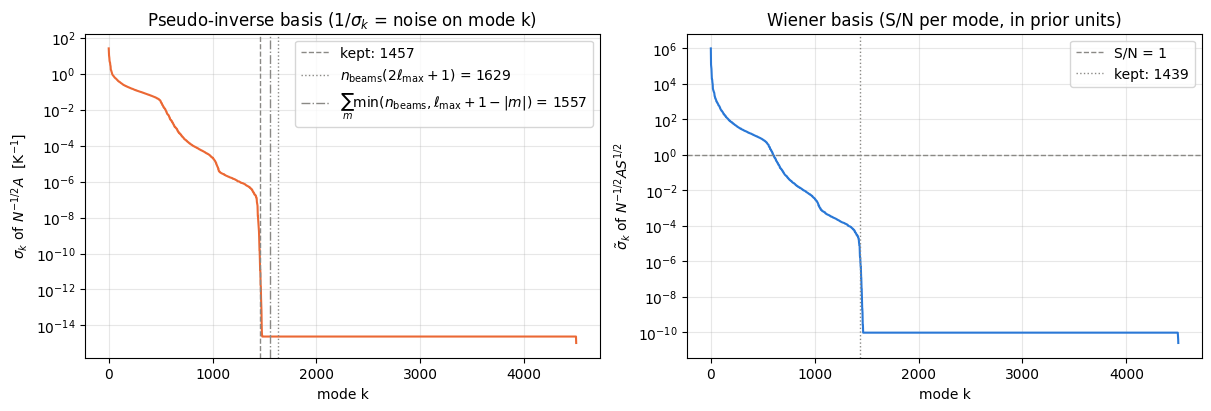

In [9]:
k_all = np.arange(1, sp_all.size + 1)
fig_spec, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 4), constrained_layout=True
)
ax1.semilogy(k_all, sp_all, color=C_PINV, lw=1.5)
ax1.axvline(kp, color=C_MUTED, ls="--", lw=1, label=f"kept: {kp}")
ax1.axvline(
    n_beams * mode_ceiling,
    color=C_MUTED,
    ls=":",
    lw=1,
    label=rf"$n_{{\rm beams}}(2\ell_{{\max}}+1)$ = {n_beams * mode_ceiling}",
)
ax1.axvline(
    m_ceiling.sum(),
    color=C_MUTED,
    ls="-.",
    lw=1,
    label=r"$\sum_m \min(n_{\rm beams}, \ell_{\max}+1-|m|)$"
    f" = {m_ceiling.sum()}",
)
ax1.set(
    xlabel="mode k",
    ylabel=r"$\sigma_k$ of $N^{-1/2}A$  [K$^{-1}$]",
    title=r"Pseudo-inverse basis ($1/\sigma_k$ = noise on mode k)",
)
ax1.legend()
ax1.grid(alpha=0.3)

ax2.semilogy(k_all[: sw_all.size], sw_all, color=C_WIENER, lw=1.5)
ax2.axhline(1, color=C_MUTED, ls="--", lw=1, label="S/N = 1")
ax2.axvline(kw, color=C_MUTED, ls=":", lw=1, label=f"kept: {kw}")
ax2.set(
    xlabel="mode k",
    ylabel=r"$\tilde\sigma_k$ of $N^{-1/2}AS^{1/2}$",
    title="Wiener basis (S/N per mode, in prior units)",
)
ax2.legend()
ax2.grid(alpha=0.3)
plt.show()

beam                      rank  >1e-3 max  sigma_max
mars-csa2022-dip           181          9       14.5
mars-mono-analytic          67         39       10.9
nv-dip                     181         19       11.4
nv-mono-analytic           177        147       8.69
mars-lake-dip              181         11       16.2
alma-csa2022-dip           181         23       11.6
alma-mono-analytic         181        169       7.92
torres-csa2022-dip         181         17       11.8
torres-mono-analytic       155        121       7.68


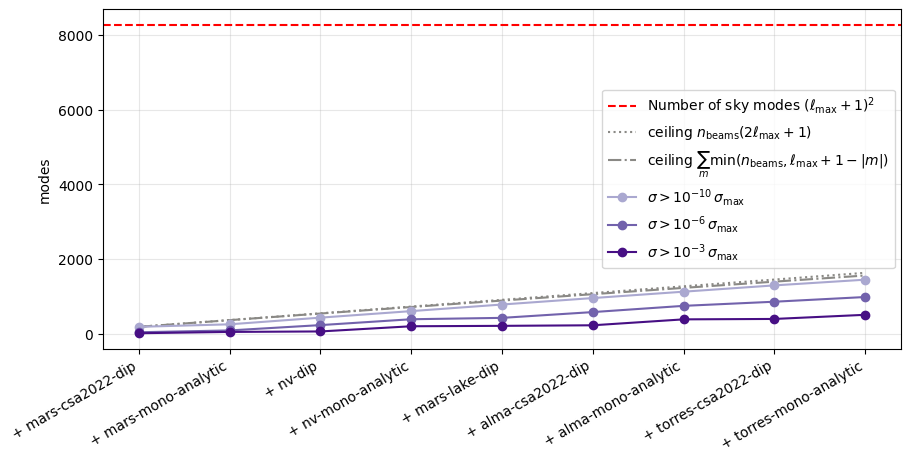

In [10]:
print(f"{'beam':24s} {'rank':>5s} {'>1e-3 max':>10s} {'sigma_max':>10s}")
for name, sv in zip(beam_names, svd["beam_sv"]):
    print(
        f"{name:24s} {np.sum(sv > 1e-10 * sv[0]):5d}"
        f" {np.sum(sv > 1e-3 * sv[0]):10d} {sv[0]:10.3g}"
    )

nb = np.arange(1, n_beams + 1)
fig_rank, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.axhline(
    (LMAX + 1) ** 2,
    ls="--",
    c="red",
    label="Number of sky modes $\\left(\\ell_{\\max}+1\\right)^2$",
)
ax.plot(
    nb,
    nb * mode_ceiling,
    color=C_MUTED,
    ls=":",
    label=r"ceiling $n_{\rm beams}(2\ell_{\max}+1)$",
)
ax.plot(
    nb,
    [
        sum(min(k, LMAX + 1 - abs(m)) for m in range(-LMAX, LMAX + 1))
        for k in nb
    ],
    color=C_MUTED,
    ls="-.",
    label=r"ceiling $\sum_m \min(n_{\rm beams}, \ell_{\max}+1-|m|)$",
)
for tol, shade in zip([1e-10, 1e-6, 1e-3], [0.45, 0.7, 0.95]):
    # for tol, shade in zip([1e-10], [0.45]):
    counts = (svd["stack_sv"] > tol * sp_all[0]).sum(axis=1)
    ax.plot(
        nb,
        counts,
        "o-",
        color=plt.cm.Purples(shade),
        label=rf"$\sigma > 10^{{{np.log10(tol):.0f}}}\,\sigma_{{\max}}$",
    )
ax.set_xticks(nb, [f"+ {n}" for n in beam_names], rotation=30, ha="right")
ax.set(ylabel="modes")  # , title="Rank of the stack as beams are added")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Picard plot

This is the standard tool for choosing a truncation without a prior.
Project the whitened data onto the left singular vectors, $u_k^{\mathsf T}\tilde y$.

* The noise part is $\mathcal N(0, 1)$ in every mode.
* The signal part falls with $\sigma_k$.

Where the signal sinks below the noise, the modes carry noise only. Keeping
them multiplies that noise by $1/\sigma_k$.

The black line is what the prior expects for the signal in mode $k$. When
`DATA_LMAX > LMAX`, the green points are the projection of the model error
(sky at $\ell > $ `LMAX`).

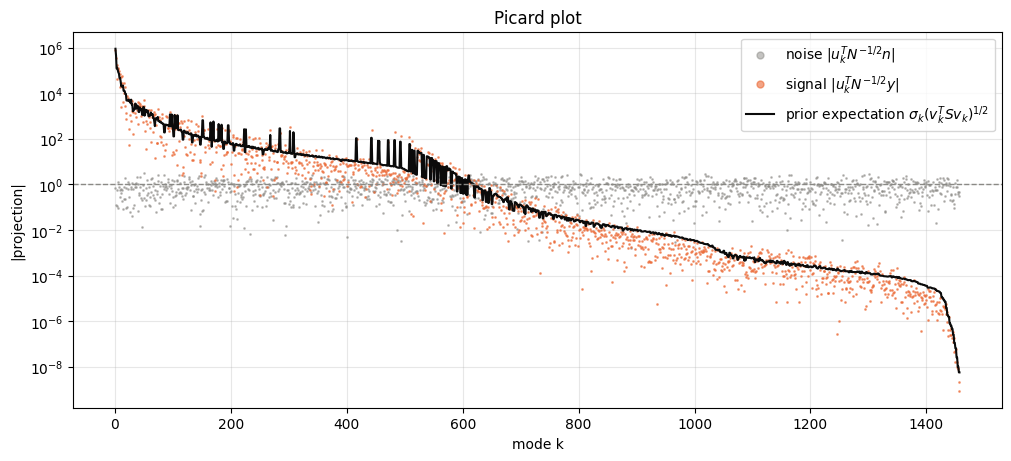

In [11]:
k_p = np.arange(1, kp + 1)
prior_sig = sp * np.sqrt((Vtp**2) @ Sdiag)

fig_picard, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.semilogy(
    k_p,
    np.abs(cp_noise),
    ".",
    ms=2,
    color=C_MUTED,
    alpha=0.5,
    label=r"noise $|u_k^T N^{-1/2} n|$",
)
ax.semilogy(
    k_p,
    np.abs(cp_sig),
    ".",
    ms=2,
    color=C_PINV,
    alpha=0.6,
    label=r"signal $|u_k^T N^{-1/2} y|$",
)
if DATA_LMAX > LMAX:
    leak = Up.T @ (Nm12 * resid_model)
    ax.semilogy(
        k_p,
        np.abs(leak),
        ".",
        ms=2,
        color=C_ROW,
        alpha=0.6,
        label=rf"model error ($\ell > {LMAX}$)",
    )
ax.semilogy(
    k_p,
    prior_sig,
    "-",
    color=C_TRUE,
    lw=1.5,
    label=r"prior expectation $\sigma_k (v_k^T S v_k)^{1/2}$",
)
ax.axhline(1, color=C_MUTED, ls="--", lw=1)
ax.set(xlabel="mode k", ylabel="|projection|", title="Picard plot")
ax.legend(markerscale=5)
ax.grid(alpha=0.3)
plt.show()

### Picard plot from the data alone

The plot above splits each coefficient into signal and noise, which only a
simulation can do. Real data give only the sum $c_k = u_k^{\mathsf T}\tilde y$.
If $N$ is right, the noise part is still $\mathcal N(0, 1)$ and independent
between modes, so $\mathbb E[c_k^2] = s_k^2 + 1$, where $s_k$ is the signal
part (the orange points above).

* **Top:** $|c_k|$ and the noise level 1, on the same axes as the plot above.
  Where the signal is far above 1 the noise barely moves it. Past the knee the
  points are $|\mathcal N(0, 1)|$, which on a log axis reaches well below 1.
* **Bottom:** the running mean of $c_k^2$ over `PICARD_WINDOW` modes. It
  estimates the local $\mathrm{SNR}^2 + 1$, so SNR = 1 is where it crosses 2.
  The data-only cut `r_picard` keeps the modes before the first crossing. The
  first crossing errs early, which is the safe side: the noise grows without
  bound as $1/\sigma_k^2$, while the truncation bias is bounded by the sky
  power. The black curve is the same running mean for the noiseless
  $s_k^2 + 1$, which needs the truth.
* **Calibration of $N$.** If $N$ is right, two numbers have expectation 1:
  $\langle c_k^2 \rangle$ in the modes more than two windows past the cut, and
  $\chi^2$/dof of the whitened data outside the span of $U$, where $A$ has no
  response. Model error (`DATA_LMAX > LMAX`) adds power to both, so an excess
  cannot tell a wrong $N$ from a wrong model.

Compare `r_picard` with the oracle ranks of section 4, which use the truth.

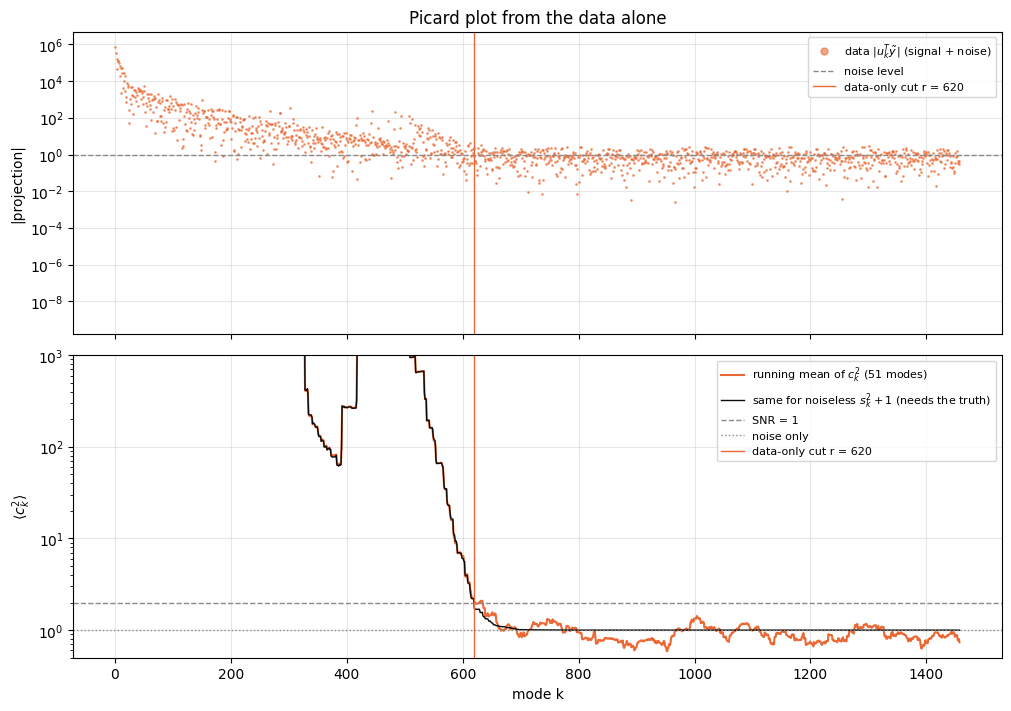

data-only cut: r = 620, 1/sigma_r = 574 K
same cut from the noiseless data: r = 619
noise calibration (both 1 if N is right and there is no model error):
  <c_k^2>, modes k > 722: 0.915 +- 0.052
  chi^2 / dof outside span(U): 0.970 +- 0.026 (3043 dof)


In [12]:
def running_mean(v, w):
    """Centred running mean over w points, narrower at the ends."""
    kern = np.ones(w)
    return np.convolve(v, kern, "same") / np.convolve(
        np.ones_like(v), kern, "same"
    )


def n_before_below(v, level):
    """Number of leading modes before v first drops below level."""
    below = np.flatnonzero(v < level)
    return int(below[0]) if below.size else v.size


c_obs = cp_sig + cp_noise  # u_k^T y_tilde: all that real data give
pow_obs = running_mean(c_obs**2, PICARD_WINDOW)
pow_true = running_mean(cp_sig**2, PICARD_WINDOW) + 1  # needs the truth
r_picard = n_before_below(pow_obs, 2)
r_picard_true = n_before_below(pow_true, 2)

# calibration of N: modes well past the cut, and data outside span(U)
tail = c_obs[r_picard + 2 * PICARD_WINDOW :]
resid_out = s_sig + s_noise - Up @ c_obs
dof_out = ndata - kp

fig_obs, (ax_o, ax_pw) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, constrained_layout=True
)
ax_o.semilogy(
    k_p,
    np.abs(c_obs),
    ".",
    ms=2,
    color=C_PINV,
    alpha=0.6,
    label=r"data $|u_k^T \tilde y|$ (signal + noise)",
)
ax_o.axhline(1, color=C_MUTED, ls="--", lw=1, label="noise level")
ax_o.set(
    ylabel="|projection|",
    ylim=fig_picard.axes[0].get_ylim(),  # same axes as the plot above
    title="Picard plot from the data alone",
)
ax_pw.semilogy(
    k_p,
    pow_obs,
    color=C_PINV,
    lw=1.5,
    label=rf"running mean of $c_k^2$ ({PICARD_WINDOW} modes)",
)
ax_pw.semilogy(
    k_p,
    pow_true,
    color=C_TRUE,
    lw=1,
    label=r"same for noiseless $s_k^2 + 1$ (needs the truth)",
)
ax_pw.axhline(2, color=C_MUTED, ls="--", lw=1, label="SNR = 1")
ax_pw.axhline(1, color=C_MUTED, ls=":", lw=1, label="noise only")
ax_pw.set(
    xlabel="mode k",
    ylabel=r"$\langle c_k^2 \rangle$",
    ylim=(0.5, 1e3),  # zoom on the crossing; the top panel has the rest
)
for ax in (ax_o, ax_pw):
    ax.axvline(
        r_picard, color=C_PINV, lw=1, label=f"data-only cut r = {r_picard}"
    )
    ax.legend(markerscale=5, fontsize=8)
    ax.grid(alpha=0.3)
plt.show()

print(
    f"data-only cut: r = {r_picard}, 1/sigma_r = {1 / sp[r_picard - 1]:.3g} K"
)
print(f"same cut from the noiseless data: r = {r_picard_true}")
print("noise calibration (both 1 if N is right and there is no model error):")
if tail.size:
    print(
        f"  <c_k^2>, modes k > {r_picard + 2 * PICARD_WINDOW}:"
        f" {tail @ tail / tail.size:.3f} +- {np.sqrt(2 / tail.size):.3f}"
    )
print(
    f"  chi^2 / dof outside span(U): {resid_out @ resid_out / dof_out:.3f}"
    f" +- {np.sqrt(2 / dof_out):.3f} ({dof_out} dof)"
)

## 4. Estimators

All estimators come from the SVD products above. Derivation of the $\beta$
dependence: with $N \to \beta N$, $A_w \to A_w/\sqrt\beta$ and
$\tilde y \to (N^{-1/2}y)/\sqrt\beta + N^{-1/2}n$. The pseudo-inverse
coefficients are then $(u_k^{\mathsf T}N^{-1/2}y + \sqrt\beta\,
u_k^{\mathsf T}N^{-1/2}n)/\sigma_k$.

$\chi^2$ is always computed directly against the dense $A$, never from the
SVD.

The checks below compare each estimator with an independent computation.

The **oracle rank** minimizes the realized error. It uses the truth, so it
is only a reference point for tuning, not something the data alone can
provide.

In [13]:
@lru_cache(maxsize=32)
def wiener(log_alpha, log_beta):
    a, b = 10.0**log_alpha, 10.0**log_beta
    sig = sw * np.sqrt(a / b)
    D = sig / (1 + sig**2)
    coef = np.sqrt(a) * D * (cw_sig / np.sqrt(b) + cw_noise)
    return {
        "a": a,
        "coef": coef,  # x_W = coef @ (S12 * Vtw)
        "x": S12 * (coef @ Vtw),
        "shrink": sig**2 / (1 + sig**2),  # prior variance removed
    }


@lru_cache(maxsize=8)
def pinv_coef(log_beta):
    """Coefficients of x+ in the V basis: x+_r = coef[:r] @ Vtp[:r]."""
    return (cp_sig + np.sqrt(10.0**log_beta) * cp_noise) / sp


def pinv(r, log_beta):
    return pinv_coef(log_beta)[:r] @ Vtp[:r]


def chi2(x, log_beta):
    """chi^2 of sky x against the data, for noise covariance beta N."""
    b = 10.0**log_beta
    res = (s_sig + np.sqrt(b) * s_noise - Nm12 * (A @ x)) / np.sqrt(b)
    return res @ res


@lru_cache(maxsize=8)
def pinv_curves(log_beta, scope):
    """Sky-RMS errors of x+_r for every r = 1..kp, restricted to scope."""
    b = 10.0**log_beta
    coef = pinv_coef(log_beta)
    if scope == "full":  # V is orthonormal, so errors add mode by mode
        bias = x_true @ x_true - np.cumsum(t_p**2)
        total = np.cumsum((coef - t_p) ** 2) + bias
        noise = b * np.cumsum(1 / sp**2)
    else:
        sel = SCOPES[scope]
        V, xs = Vtp[:, sel], x_true[sel]
        est = np.cumsum(coef[:, None] * V, axis=0)
        ideal = np.cumsum(t_p[:, None] * V, axis=0)
        total = ((est - xs) ** 2).sum(axis=1)
        bias = ((ideal - xs) ** 2).sum(axis=1)
        noise = b * np.cumsum((V**2).sum(axis=1) / sp**2)
    curves = {"total": total, "noise": noise, "bias": bias}
    return {k: rms(np.clip(v, 0, None)) for k, v in curves.items()}


@lru_cache(maxsize=32)
def split_curves(log_alpha, log_beta):
    """Errors inside row(A_r) and in its complement, for every r."""
    p_row = np.cumsum((pinv_coef(log_beta) - t_p) ** 2)
    p_ker = x_true @ x_true - np.cumsum(t_p**2)
    d = wiener(log_alpha, log_beta)["x"] - x_true
    w_row = np.cumsum((Vtp @ d) ** 2)
    w_ker = d @ d - w_row
    curves = {"p_row": p_row, "p_ker": p_ker, "w_row": w_row, "w_ker": w_ker}
    return {k: rms(np.clip(v, 0, None)) for k, v in curves.items()}


r_best = {
    sc: int(np.argmin(pinv_curves(0.0, sc)["total"])) + 1 for sc in SCOPES
}
print("oracle rank (minimum realized error; uses the truth):")
for sc, r in r_best.items():
    print(
        f"  {SCOPE_LABEL[sc]:8s} r = {r:5d}"
        f"   1/sigma_r = {1 / sp[r - 1]:.3g} K"
    )

oracle rank (minimum realized error; uses the truth):
  ℓ ≤ 10   r =  1451   1/sigma_r = 2.37e+09 K
  ℓ ≤ 90   r =   609   1/sigma_r = 438 K


In [14]:
t0 = time.time()
y_tilde = s_sig + s_noise

# SVDs reproduce the matrices they came from
Aw_rec = (Up * sp) @ Vtp
rec_err = np.linalg.norm(Nm12[:, None] * A - Aw_rec) / np.linalg.norm(Aw_rec)
print(f"|A_w - U S V^T| / |A_w| = {rec_err:.1e}")
del Aw_rec

# Wiener: SVD formula vs a direct solve in data space,
# x_W = S^1/2 At^T (At At^T + I)^-1 y_tilde
At = (Nm12[:, None] * A) * S12
G = At @ At.T
G[np.diag_indices_from(G)] += 1
x_direct = S12 * (At.T @ sla.solve(G, y_tilde, assume_a="pos"))
del At, G
x_w1 = wiener(0.0, 0.0)["x"]
print(
    f"Wiener, SVD vs direct solve: rel. diff "
    f"{np.linalg.norm(x_w1 - x_direct) / np.linalg.norm(x_direct):.1e}"
)

# pseudo-inverse: residual orthogonal to the kept modes, checked
# against the dense A rather than the SVD
r = r_best["large"]
res = y_tilde - Nm12 * (A @ pinv(r, 0.0))
proj = Up[:, :r].T
print(
    f"pinv at r = {r}: |U_r^T res| / |U_r^T y| = "
    f"{np.linalg.norm(proj @ res) / np.linalg.norm(proj @ y_tilde):.1e}"
)

# packed C_ell helper vs healpy
cl_ref = hp.alm2cl(packed_to_hp(x_true)[0])
print(
    f"cl_packed vs hp.alm2cl: max rel. diff "
    f"{np.max(np.abs(cl_packed(x_true) / cl_ref - 1)):.1e}"
)
print(f"checks: {time.time() - t0:.0f} s")

|A_w - U S V^T| / |A_w| = 5.1e-13
Wiener, SVD vs direct solve: rel. diff 8.0e-07
pinv at r = 1451: |U_r^T res| / |U_r^T y| = 2.0e-11
cl_packed vs hp.alm2cl: max rel. diff 8.9e-16
checks: 14 s


### Precomputed maps

Maps of every kept right singular vector, in both scopes. After this, every
map in the panels is a matrix-vector product.

* `Bp`: maps of $v_k$ (pseudo-inverse basis).
* `Bw`: maps of $S^{1/2}\tilde v_k$ (Wiener basis).

The Wiener posterior variance map is the exact low-rank downdate of the
prior, $\alpha\,[\sigma^2_{\rm prior} - \sum_k M_k (Y S^{1/2}\tilde v_k)^2]$
with $M_k = \tilde\sigma_k^2/(1+\tilde\sigma_k^2)$.

$z$ are draws from the prior, used as the "arbitrary" kernel vectors.

In [15]:
t0 = time.time()
Bp = {sc: maps_of(Vtp, sc) for sc in SCOPES}
Bw = {sc: maps_of(S12 * Vtw, sc) for sc in SCOPES}
Bp_sq = {sc: B**2 for sc, B in Bp.items()}  # for the std maps
Bw_sq = {sc: B**2 for sc, B in Bw.items()}
truth_map = {sc: maps_of(x_true, sc)[0] for sc in SCOPES}
prior_var = {sc: Sdiag[SCOPES[sc]].sum() / (4 * np.pi) for sc in SCOPES}

rng = np.random.default_rng(SEED)
z_draws = S12 * rng.normal(size=(N_KERNEL_DRAWS, nalm))
z_map = {sc: maps_of(z_draws, sc) for sc in SCOPES}

nbytes = sum(b.nbytes for d in (Bp, Bw, Bp_sq, Bw_sq) for b in d.values())
print(f"basis maps: {time.time() - t0:.0f} s, {nbytes / 1e9:.2f} GB")

basis maps: 43 s, 1.14 GB


In [16]:
SLIDER = {"continuous_update": False, "style": {"description_width": "70px"}}
w_alpha = widgets.FloatSlider(
    value=0.0,
    min=-3.0,
    max=3.0,
    step=0.1,
    description="log₁₀ α",
    readout_format=".1f",
    **SLIDER,
)
w_beta = widgets.FloatSlider(
    value=0.0,
    min=-2.0,
    max=4.0,
    step=0.1,
    description="log₁₀ β",
    readout_format=".1f",
    **SLIDER,
)
w_rank = widgets.IntSlider(
    value=r_best["large"], min=1, max=kp, description="rank r", **SLIDER
)
w_scope = widgets.ToggleButtons(
    options=[(SCOPE_LABEL["large"], "large"), (SCOPE_LABEL["full"], "full")],
    value="large",
    description="maps",
    style={"button_width": "80px"},
)

## 5. Wiener filter

**Knobs:** $\alpha$ scales the prior and $\beta$ scales the noise.

**Top panel:** the filter factor $M_k = \tilde\sigma_k^2/(1+\tilde\sigma_k^2)$.
It is 1 where the data dominate and 0 where the prior dominates. Its sum is
the effective number of measured modes. The pseudo-inverse's equivalent is a
step function: 1 for $k \le r$, 0 after.

**Maps:** the truth, $x_W$, the error, and the posterior standard deviation.

Things to look for:
* $\alpha \ll 1$ shrinks everything towards zero.
* $\alpha \gg 1$ lets noise through in the poorly measured modes and
  approaches the minimum-$S^{-1}$-norm pseudo-inverse.

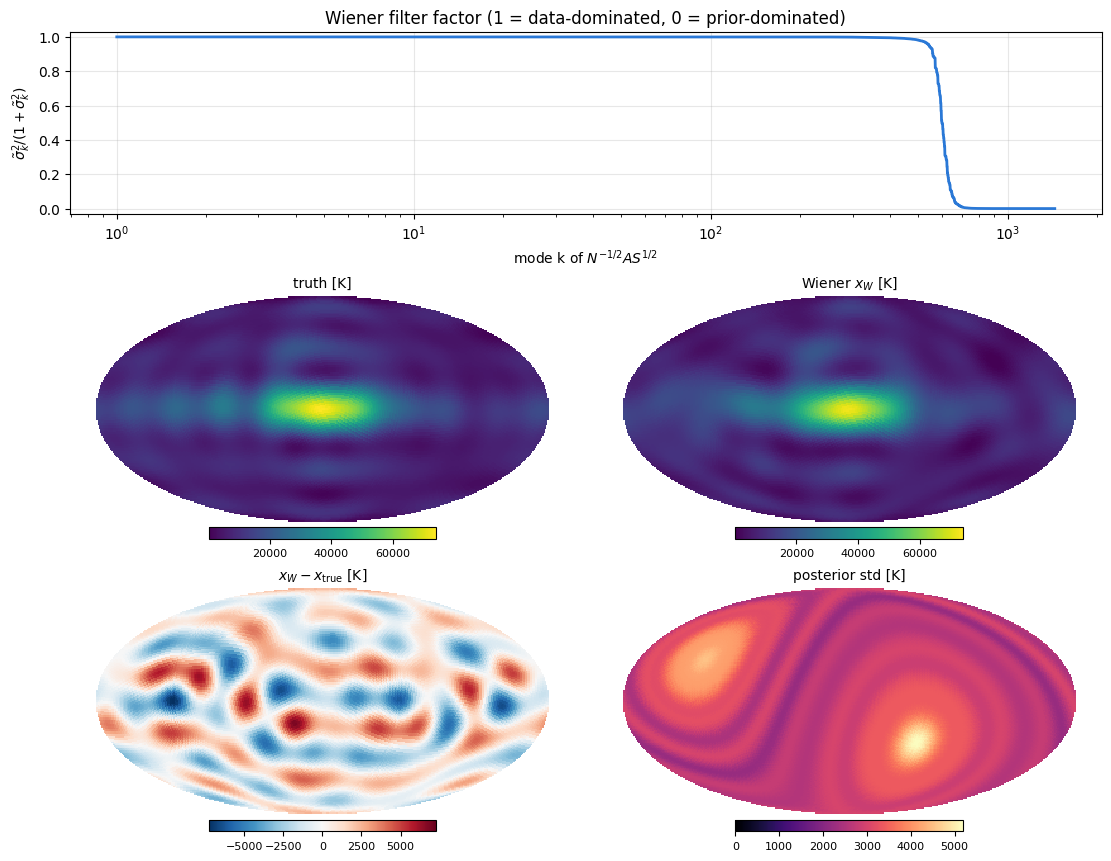

,"sky RMS error, ℓ ≤ 10",fractional map residual,effective dof,χ² / N_data
Wiener,2.32e+03 K,0.347,600.3,0.8314


In [17]:
with plt.ioff():
    fig_w = plt.figure(figsize=(11, 8.5), constrained_layout=True)
    gs = fig_w.add_gridspec(3, 2, height_ratios=[0.8, 1, 1])
    ax_f = fig_w.add_subplot(gs[0, :])
    ax_wm = [fig_w.add_subplot(gs[1 + i // 2, i % 2]) for i in range(4)]
fig_w.canvas.header_visible = False

(line_shrink,) = ax_f.semilogx(
    np.arange(1, kw + 1), np.zeros(kw), color=C_WIENER, lw=2
)
ax_f.set(
    xlabel=r"mode k of $N^{-1/2}AS^{1/2}$",
    ylabel=r"$\tilde\sigma_k^2 / (1 + \tilde\sigma_k^2)$",
    ylim=(-0.03, 1.03),
    title="Wiener filter factor (1 = data-dominated, 0 = prior-dominated)",
)
ax_f.grid(alpha=0.3)
im_w = [
    moll_image(ax, t, cmap)
    for ax, t, cmap in zip(
        ax_wm,
        [
            "truth [K]",
            "Wiener $x_W$ [K]",
            "$x_W - x_{\\rm true}$ [K]",
            "posterior std [K]",
        ],
        ["viridis", "viridis", "RdBu_r", "magma"],
    )
]
info_w = widgets.HTML()


def update_wiener():
    la, lb, sc = w_alpha.value, w_beta.value, w_scope.value
    W = wiener(la, lb)
    line_shrink.set_ydata(W["shrink"])
    m_true = truth_map[sc]
    m_w = W["coef"] @ Bw[sc]
    var = W["a"] * (prior_var[sc] - W["shrink"] @ Bw_sq[sc])
    std = np.sqrt(np.clip(var, 0, None))
    lim = (m_true.min(), m_true.max())
    set_map(im_w[0], m_true, lim)
    set_map(im_w[1], m_w, lim)
    set_map(im_w[2], m_w - m_true, symmetric=True)
    set_map(im_w[3], std, (0, std.max()))
    d = (W["x"] - x_true)[SCOPES[sc]]
    info_w.value = html_table(
        {
            "Wiener": {
                f"sky RMS error, {SCOPE_LABEL[sc]}": f"{rms(d @ d):.3g} K",
                "fractional map residual": f"{frac_rms(m_w, m_true):.3g}",
                "effective dof": f"{W['shrink'].sum():.1f}",
                "χ² / N_data": f"{chi2(W['x'], lb) / ndata:.4f}",
            }
        }
    )
    fig_w.canvas.draw_idle()


err_w = connect(update_wiener, [w_alpha, w_beta, w_scope])
show_panel(widgets.HBox([w_alpha, w_beta, w_scope]), fig_w, info_w, err_w)

## 6. Pseudo-inverse

**Knobs:** the rank $r$ and the noise scale $\beta$.

**Top left:** the sky-RMS error of $x^+_r$ against $r$, split into two
parts.
* Noise: $\beta \sum_{k \le r} \lVert v_k \rVert^2 / \sigma_k^2$, restricted
  to the scope.
* Truncation bias: the error of the noiseless $P_r x_{\rm true}$. This
  includes the part of the truth in the exact kernel, which no $r$ can
  recover.

The realized total also contains model error when `DATA_LMAX > LMAX`. The
blue line is the Wiener error, for scale.

**Top right:** the Picard plot, with the signal scaled by $1/\sqrt\beta$.

**Maps:**
* the truth
* $P_r x_{\rm true}$: the best any rank-$r$ pseudo-inverse can do
* $x^+_r$
* its noise $x^+_r - P_r x_{\rm true}$
* its total error
* the row-space noise standard deviation

The kernel part has no standard deviation at all: it is unconstrained.

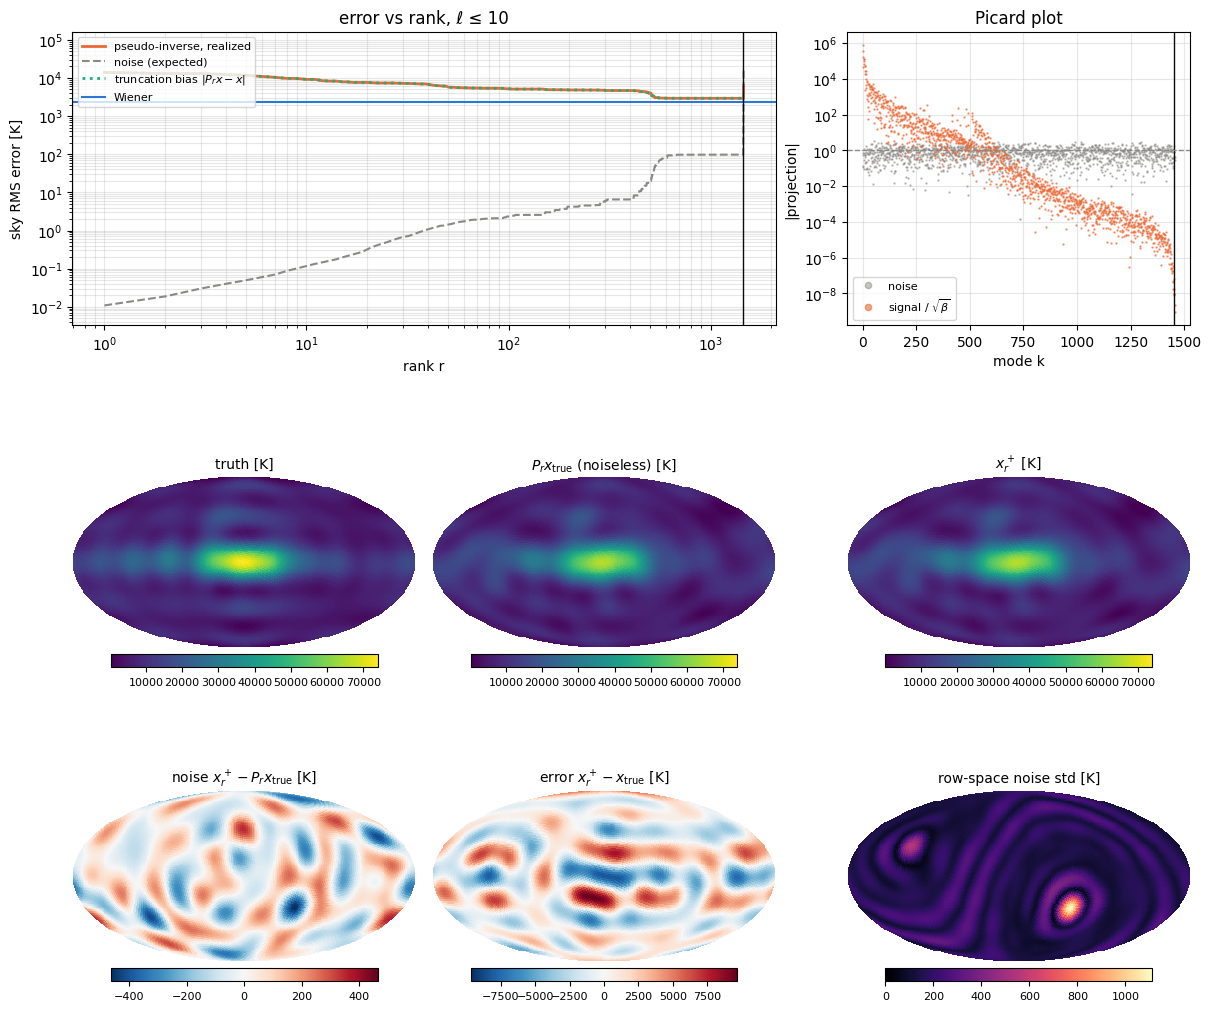

,1/σ_r (noise cut),"sky RMS error, ℓ ≤ 10",fractional map residual,kernel dim (numerical),χ² / N_data
"pseudo-inverse, r = 1451",2.37e+09 K,2.91e+03 K,0.5,6830,0.6570


In [18]:
with plt.ioff():
    fig_p = plt.figure(figsize=(12, 10), constrained_layout=True)
    gs = fig_p.add_gridspec(3, 3, height_ratios=[1.1, 1, 1])
    ax_c = fig_p.add_subplot(gs[0, :2])
    ax_pic = fig_p.add_subplot(gs[0, 2])
    ax_pm = [fig_p.add_subplot(gs[1 + i // 3, i % 3]) for i in range(6)]
fig_p.canvas.header_visible = False

lines_c = {
    "total": ax_c.loglog(
        k_p, k_p * 1.0, color=C_PINV, lw=2, label="pseudo-inverse, realized"
    )[0],
    "noise": ax_c.loglog(
        k_p,
        k_p * 1.0,
        color=C_MUTED,
        ls="--",
        lw=1.5,
        label="noise (expected)",
    )[0],
    "bias": ax_c.loglog(
        k_p,
        k_p * 1.0,
        color=C_ROW,
        ls=":",
        lw=2,
        label=r"truncation bias $|P_r x - x|$",
    )[0],
}
wline_c = ax_c.axhline(1, color=C_WIENER, lw=1.5, label="Wiener")
rline_c = ax_c.axvline(1, color=C_TRUE, lw=1)
ax_c.set(xlabel="rank r", ylabel="sky RMS error [K]")
ax_c.legend(fontsize=8, loc="upper left")
ax_c.grid(alpha=0.3, which="both")

ax_pic.semilogy(
    k_p,
    np.abs(cp_noise),
    ".",
    ms=1.5,
    color=C_MUTED,
    alpha=0.5,
    label="noise",
)
(sig_pts,) = ax_pic.semilogy(
    k_p,
    np.abs(cp_sig),
    ".",
    ms=1.5,
    color=C_PINV,
    alpha=0.6,
    label=r"signal / $\sqrt{\beta}$",
)
rline_pic = ax_pic.axvline(1, color=C_TRUE, lw=1)
ax_pic.axhline(1, color=C_MUTED, ls="--", lw=1)
ax_pic.set(xlabel="mode k", ylabel="|projection|", title="Picard plot")
ax_pic.legend(fontsize=8, markerscale=6)
ax_pic.grid(alpha=0.3)

im_p = [
    moll_image(ax, t, cmap)
    for ax, t, cmap in zip(
        ax_pm,
        [
            "truth [K]",
            "$P_r x_{\\rm true}$ (noiseless) [K]",
            "$x^+_r$ [K]",
            ("noise" if DATA_LMAX == LMAX else "noise + model error")
            + " $x^+_r - P_r x_{\\rm true}$ [K]",
            "error $x^+_r - x_{\\rm true}$ [K]",
            "row-space noise std [K]",
        ],
        ["viridis", "viridis", "viridis", "RdBu_r", "RdBu_r", "magma"],
    )
]
info_p = widgets.HTML()


def update_pinv():
    la, lb, r, sc = w_alpha.value, w_beta.value, w_rank.value, w_scope.value
    b = 10.0**lb
    curves = pinv_curves(lb, sc)
    for key, line in lines_c.items():
        line.set_ydata(curves[key])
    dW = (wiener(la, lb)["x"] - x_true)[SCOPES[sc]]
    wline_c.set_ydata([rms(dW @ dW)] * 2)
    truth_rms = rms(x_true[SCOPES[sc]] @ x_true[SCOPES[sc]])
    floor = min(curves["noise"][0], curves["total"].min(), rms(dW @ dW))
    ax_c.set_ylim(0.3 * floor, 10 * truth_rms)
    ax_c.set_title(f"error vs rank, {SCOPE_LABEL[sc]}")
    rline_c.set_xdata([r, r])
    rline_pic.set_xdata([r, r])
    sig_pts.set_ydata(np.abs(cp_sig) / np.sqrt(b))

    coef = pinv_coef(lb)[:r]
    B = Bp[sc][:r]
    m_true, m_p, m_row = truth_map[sc], coef @ B, t_p[:r] @ B
    std = np.sqrt(b * (sp[:r] ** -2 @ Bp_sq[sc][:r]))
    lim = (m_true.min(), m_true.max())
    set_map(im_p[0], m_true, lim)
    set_map(im_p[1], m_row, lim)
    set_map(im_p[2], m_p, lim)
    set_map(im_p[3], m_p - m_row, symmetric=True)
    set_map(im_p[4], m_p - m_true, symmetric=True)
    set_map(im_p[5], std, (0, std.max()))

    x_p = coef @ Vtp[:r]
    d = (x_p - x_true)[SCOPES[sc]]
    info_p.value = html_table(
        {
            f"pseudo-inverse, r = {r}": {
                "1/σ_r (noise cut)": f"{np.sqrt(b) / sp[r - 1]:.3g} K",
                f"sky RMS error, {SCOPE_LABEL[sc]}": f"{rms(d @ d):.3g} K",
                "fractional map residual": f"{frac_rms(m_p, m_true):.3g}",
                "kernel dim (numerical)": f"{nalm - r}",
                "χ² / N_data": f"{chi2(x_p, lb) / ndata:.4f}",
            }
        }
    )
    fig_p.canvas.draw_idle()


err_p = connect(update_pinv, [w_alpha, w_beta, w_rank, w_scope])
show_panel(widgets.HBox([w_rank, w_beta, w_scope]), fig_p, info_p, err_p)

## 7. The kernel: $x = x^+_r + (I - P_r)\,z$

$P_r = V_r V_r^{\mathsf T}$ projects onto the kept row space. Its complement
is the kernel: the exact kernel of $A$ plus the modes cut at rank $r$.

**Top left:** the diagonal of $P_r$ on the $(\ell, m)$ plane, the fraction
of each harmonic direction the data constrain. $m > 0$ averages the real and
imaginary parts.

**Top right, per $\ell$:**
* the relative error of the noiseless pseudo-inverse,
  $\lVert [(I - P_r)x]_\ell \rVert^2 / \lVert x_\ell \rVert^2$;
* the fraction of the $(\ell, m)$ directions that lie in the kernel.

**Middle row:**
* the truth
* the truth's kernel part: what the data cannot see
* the Wiener estimate's kernel part: what the prior fills in

**Bottom row:** three members of the solution family,
$x^+_r + (I - P_r)z$, with $z$ drawn from the prior. The table shows that
they fit the data equally well. At $r$ = full rank, $\Delta\chi^2 \approx 0$.
Below that, the cut modes carry a little data weight.

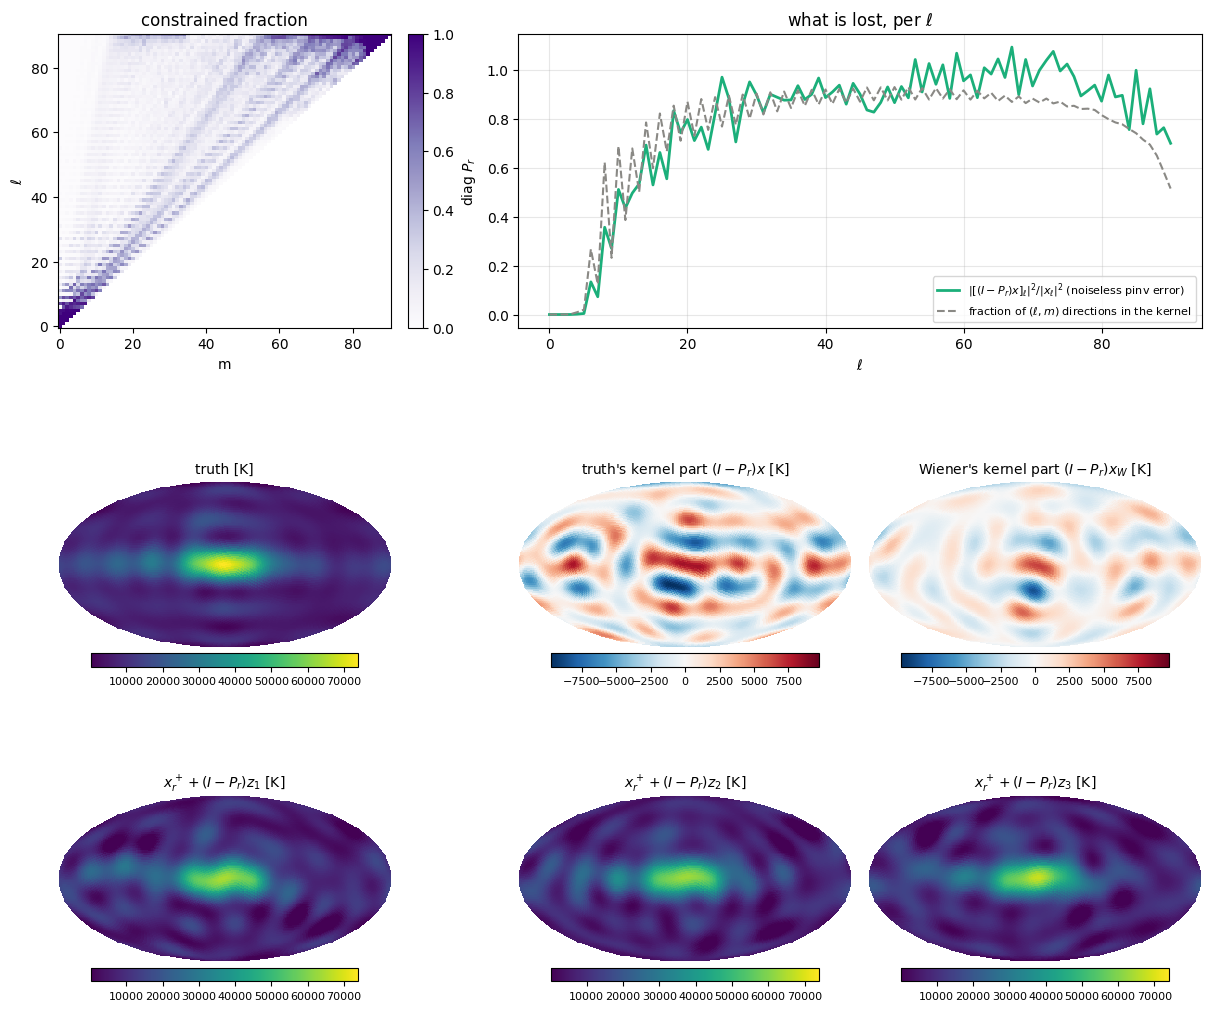

,χ² / N_data,Δχ² vs x⁺
x_true,0.962210,
x⁺_r,0.657042,0
x⁺_r + (I-P_r) z_1,0.657042,1.51e-08
x⁺_r + (I-P_r) z_2,0.657042,-1.42e-07
x⁺_r + (I-P_r) z_3,0.657042,-1.78e-08


In [19]:
with plt.ioff():
    fig_k = plt.figure(figsize=(12, 10), constrained_layout=True)
    gs = fig_k.add_gridspec(3, 3, height_ratios=[1.1, 1, 1])
    ax_lm = fig_k.add_subplot(gs[0, 0])
    ax_ell = fig_k.add_subplot(gs[0, 1:])
    ax_km = [fig_k.add_subplot(gs[1 + i // 3, i % 3]) for i in range(6)]
fig_k.canvas.header_visible = False

im_lm = ax_lm.imshow(
    lm_image(np.zeros(nalm)),
    origin="lower",
    cmap="Purples",
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest",
)
fig_k.colorbar(im_lm, ax=ax_lm, label=r"diag $P_r$")
ax_lm.set(xlabel="m", ylabel=r"$\ell$", title="constrained fraction")

ells = np.arange(L1)
(line_bias_ell,) = ax_ell.plot(
    ells,
    np.zeros(L1),
    color=C_ROW,
    lw=2,
    label=r"$|[(I-P_r)x]_\ell|^2 / |x_\ell|^2$ (noiseless pinv error)",
)
(line_kdir_ell,) = ax_ell.plot(
    ells,
    np.zeros(L1),
    color=C_MUTED,
    ls="--",
    lw=1.5,
    label=r"fraction of $(\ell, m)$ directions in the kernel",
)
ax_ell.set(xlabel=r"$\ell$", title=r"what is lost, per $\ell$")
ax_ell.legend(fontsize=8)
ax_ell.grid(alpha=0.3)

titles = [
    "truth [K]",
    "truth's kernel part $(I-P_r)x$ [K]",
    "Wiener's kernel part $(I-P_r)x_W$ [K]",
]
titles += [f"$x^+_r + (I-P_r)z_{i + 1}$ [K]" for i in range(3)]
cmaps = ["viridis", "RdBu_r", "RdBu_r", "viridis", "viridis", "viridis"]
im_k = [moll_image(ax, t, cm) for ax, t, cm in zip(ax_km, titles, cmaps)]
info_k = widgets.HTML()


def update_kernel():
    la, lb, r, sc = w_alpha.value, w_beta.value, w_rank.value, w_scope.value
    diag = np.sum(Vtp[:r] ** 2, axis=0)
    im_lm.set_data(lm_image(diag))
    x_row = t_p[:r] @ Vtp[:r]
    line_bias_ell.set_ydata(cl_packed(x_true - x_row) / cl_packed(x_true))
    line_kdir_ell.set_ydata(1 - np.bincount(ell_p, diag) / (2 * ells + 1))
    ax_ell.relim()
    ax_ell.autoscale_view()

    B = Bp[sc][:r]
    x_w = wiener(la, lb)["x"]
    m_true = truth_map[sc]
    m_p = pinv_coef(lb)[:r] @ B
    m_ker_true = m_true - t_p[:r] @ B
    m_ker_w = wiener(la, lb)["coef"] @ Bw[sc] - (Vtp[:r] @ x_w) @ B
    lim = (m_true.min(), m_true.max())
    set_map(im_k[0], m_true, lim)
    ker_lim = np.max(np.abs(np.concatenate([m_ker_true, m_ker_w])))
    set_map(im_k[1], m_ker_true, ker_lim, symmetric=True)
    set_map(im_k[2], m_ker_w, ker_lim, symmetric=True)

    x_p = pinv(r, lb)
    rows = {
        "x_true": {
            "χ² / N_data": f"{chi2(x_true, lb) / ndata:.6f}",
            "Δχ² vs x⁺": "",
        },
        "x⁺_r": {
            "χ² / N_data": f"{chi2(x_p, lb) / ndata:.6f}",
            "Δχ² vs x⁺": "0",
        },
    }
    chi_p = chi2(x_p, lb)
    for i, z in enumerate(z_draws):
        pz = Vtp[:r] @ z
        member = x_p + z - pz @ Vtp[:r]
        set_map(im_k[3 + i], m_p + z_map[sc][i] - pz @ B, lim)
        c2 = chi2(member, lb)
        rows[f"x⁺_r + (I-P_r) z_{i + 1}"] = {
            "χ² / N_data": f"{c2 / ndata:.6f}",
            "Δχ² vs x⁺": f"{c2 - chi_p:.3g}",
        }
    info_k.value = (
        f"<b>r = {r}</b>: numerical kernel dimension {nalm - r}"
        f" (exact kernel {nalm - kp}), N_data = {ndata}<br>" + html_table(rows)
    )
    fig_k.canvas.draw_idle()


err_k = connect(update_kernel, [w_alpha, w_beta, w_rank, w_scope])
show_panel(widgets.HBox([w_rank, w_alpha, w_scope]), fig_k, info_k, err_k)

## 7b. The row space, one $m$ at a time

Section 7 shows *how much* of each $(\ell, m)$ the data constrain. This
section shows *why*, from the $m$-mode picture of section 3.

**The problem is block-diagonal in $m$.** Earth rotation turns order $m$ into
frequency $m$ in the timestream, so the time series separates different $m$
for free. It cannot separate different $\ell$ at the same $m$: each beam gives
one number per column of the $(\ell, m)$ triangle,
$c_m = \sum_{\ell \ge |m|} a^*_{\ell m} b_{\ell m}$. Therefore:

* The row space at order $m$ has at most $n_{\rm beams}$ complex dimensions
  ($n_{\rm beams}$ real at $m = 0$): `m_ceiling[m]` in packed real
  dimensions.
* The kernel at order $m$ is everything in column $m$ orthogonal to the
  beams' $b_{\ell m}$. No integration time changes it.
* At full rank $P$ is exactly block-diagonal, because $N$ does not change
  the row space. Below full rank the noise weighting couples neighbouring
  $m$ slightly: $N$ varies with LST, and multiplying a timestream by a
  function of LST mixes its Fourier modes.

**Top left:** kept dimensions $\mathrm{tr}\,P_m$ against the ceiling.

**Top right:** the same for the $\ell \le$ `L_REP` part of each column
(`L_REP` = `PLOT_LMAX`).
* Light to medium bar: forced by counting, where column $m$ has more
  $\ell \le$ `L_REP` modes than the row space has dimensions.
* Medium to dark bar: the rest. Each constraint is a sum over *all*
  $\ell \ge |m|$, up to $\ell_{\max}$, and no combination of
  $n_{\rm beams}$ constraints isolates the low-$\ell$ part of a column.

**Bottom, for one $m$:** the $m$-block of $P_r$ as a complex
$\ell \times \ell'$ projector $\Pi$ (left), and its diagonal (right), the
fraction of each $Y_{\ell m}$ kept. The diagonal sums to the kept dimensions
(complex ones for $m > 0$) and spreads over $\ell$ well past `L_REP`. The
off-diagonal terms tie the low-$\ell$ part of the column to its high-$\ell$
part.

The next cell defines the helpers for 7b to 7d and checks them.

In [20]:
L_REP = PLOT_LMAX  # the ell cut that the reporting subspace (7c) imitates
in_low = SCOPES["large"]  # packed entries with ell <= L_REP
m_sel = [m_p == m for m in range(L1)]
low_dim = np.bincount(m_p[in_low], minlength=L1)  # real dimensions per m
low_pos = [np.flatnonzero(s[in_low]) for s in m_sel[: L_REP + 1]]
site_lats = sorted({s["lat"] for s in cfg["sites"]})


def block_traces(r):
    """tr P_m for every m >= 0: all ell, and the ell <= L_REP part."""
    diag = np.sum(Vtp[:r] ** 2, axis=0)
    return (
        np.bincount(m_p, diag, minlength=L1),
        np.bincount(m_p[in_low], diag[in_low], minlength=L1),
    )


@lru_cache(maxsize=8)
def off_block(r):
    """Fraction of |P_r|_F^2 = r that couples different m."""
    inside = sum(np.sum((Vtp[:r, s].T @ Vtp[:r, s]) ** 2) for s in m_sel)
    return 1 - inside / r


def m_block(r, m):
    """The m-block of P_r as a complex (ell, ell') matrix, ell = m..LMAX.

    For m > 0 the packed block holds the real parts, then the imaginary
    parts, and P_r acts on them as [[Re Pi, -Im Pi], [Im Pi, Re Pi]].
    """
    Vm = Vtp[:r, m_sel[m]]
    P = Vm.T @ Vm
    if m == 0:
        return P + 0j
    n = L1 - m
    return 0.5 * (P[:n, :n] + P[n:, n:]) + 0.5j * (P[n:, :n] - P[:n, n:])


@lru_cache(maxsize=8)
def principal(r):
    """Principal pairs of the rank-r row space and the ell <= L_REP space.

    SVD of V_r restricted to ell <= L_REP. Column i of G gives the
    row-space vector q_i = G[:, i] @ Vtp[:r]; cos[i] is its overlap with
    ell <= L_REP. Equal cosines at different m mix in the SVD, so
    low_directions labels directions by m instead.
    """
    G, cos, _ = np.linalg.svd(Vtp[:r, in_low], full_matrices=False)
    return cos, G


def q_basis(r, tau):
    """Columns of G with cos > tau: an orthonormal basis of Q (7c)."""
    cos, G = principal(r)
    return G[:, cos > tau]


@lru_cache(maxsize=64)
def low_directions(r, m):
    """The ell <= L_REP directions of order m, most visible first.

    Eigenvectors w of the ell <= L_REP part of the m-block of P_r, as rows
    over the packed entries low_pos[m]. The eigenvalues are
    cos^2 = w^T P_r w, the part of w inside the row space.
    """
    Vm = Vtp[:r, in_low & m_sel[m]]
    cos2, w = np.linalg.eigh(Vm.T @ Vm)
    order = np.argsort(cos2)[::-1]
    return np.sqrt(np.clip(cos2[order], 0, 1)), w[:, order].T


def coverage(r):
    """Fraction of an ell <= L_REP point source kept by P_r, per pixel.

    |P_r d|^2 / |d|^2 for the band-limited delta d at the pixel: the map
    of the ell <= L_REP part of v_k is v_k . d there, and
    |d|^2 = (L_REP + 1)^2 / 4 pi.
    """
    return 4 * np.pi * Bp_sq["large"][:r].sum(axis=0) / (L_REP + 1) ** 2


# HEALPix RING order stores the pixels ring by ring, north to south
ring_theta, ring_n = np.unique(
    hp.pix2ang(NSIDE_MAP, np.arange(NPIX))[0], return_counts=True
)
ring_dec = 90 - np.degrees(ring_theta)
ring_start = np.r_[0, np.cumsum(ring_n)[:-1]]


def ring_reduce(ufunc, maps):
    """Reduce maps (..., NPIX) over each ring of constant declination."""
    return ufunc.reduceat(maps, ring_start, axis=-1)


def dec_profile(maps, m):
    """Declination profile of order-m maps f(dec) cos(m ra + psi(dec)).

    The signed ring mean f for m = 0; the envelope |f|, sqrt(2) times the
    ring RMS, for m > 0.
    """
    if m == 0:
        return ring_reduce(np.add, maps) / ring_n
    return np.sqrt(2 * ring_reduce(np.add, maps**2) / ring_n)


def peak_normalize(prof):
    """Scale each profile to peak 1, with the peak positive."""
    i = np.abs(prof).argmax(axis=-1)[..., None]
    return prof / np.take_along_axis(prof, i, axis=-1)


@lru_cache(maxsize=None)
def beam_profiles(m):
    """Each beam's weight on the order-m sky, against declination.

    At one m a beam measures one complex number (one real number at
    m = 0), so its block of A has rank 2 (1 at m = 0). The top right
    singular vector lies in that span, and its profile is |b_m(dec)|.
    """
    rows = np.zeros((n_beams, nalm))
    for i, blk in enumerate(np.split(A, n_beams)):
        sub = blk[:, m_sel[m]]
        rows[i, m_sel[m]] = np.linalg.svd(sub, full_matrices=False)[2][0]
    return peak_normalize(dec_profile(maps_of(rows, "full"), m))


# maps of the ell <= L_REP unit vectors, for the patterns in 7d
low_unit = np.zeros((in_low.sum(), nalm))
low_unit[np.arange(in_low.sum()), np.flatnonzero(in_low)] = 1
B_low = maps_of(low_unit, "large")
del low_unit

print(f"ell <= {L_REP}: {in_low.sum()} real dimensions")
for rk in (r_picard, kp):
    tr_m, tr_low = block_traces(rk)
    cos_rk = principal(rk)[0]
    cov = coverage(rk)
    eig = sum(np.sum(low_directions(rk, m)[0] ** 2) for m in range(L_REP + 1))
    ra_range = ring_reduce(np.maximum, cov) - ring_reduce(np.minimum, cov)
    print(f"r = {rk}:")
    print(
        f"  sum_m tr P_m = {tr_m.sum():.6f}; largest tr P_m - m_ceiling"
        f" = {np.max(tr_m - m_ceiling):+.1e}"
    )
    print(f"  part of |P_r|_F^2 that couples different m: {off_block(rk):.2e}")
    print(
        f"  ell <= {L_REP} inside the row space: {tr_low.sum():.4f}; as sum"
        f" cos^2 {np.sum(cos_rk**2):.4f}; from the per-m eigenvalues"
        f" {eig:.4f}"
    )
    print(
        f"  sky mean of the coverage x (L_REP + 1)^2:"
        f" {cov.mean() * (L_REP + 1) ** 2:.4f}; its largest range over RA"
        f" at fixed dec: {ra_range.max():.1e}"
    )

# the pseudo-inverse residual in Q is noise only (7c)
Gq = q_basis(r_picard, 0.9)
d_q = Gq.T @ (pinv_coef(0.0)[:r_picard] - t_p[:r_picard])
n_q = Gq.T @ (cp_noise[:r_picard] / sp[:r_picard])
print(
    f"Q at r = {r_picard}, cos > 0.9: dim {Gq.shape[1]};"
    f" |Q(x+ - x_true) - Q noise| / |Q noise| ="
    f" {np.linalg.norm(d_q - n_q) / np.linalg.norm(n_q):.1e}"
    " (0 unless DATA_LMAX > LMAX)"
)

ell <= 10: 121 real dimensions
r = 620:
  sum_m tr P_m = 620.000000; largest tr P_m - m_ceiling = -2.5e-09
  part of |P_r|_F^2 that couples different m: 8.84e-03
  ell <= 10 inside the row space: 85.9178; as sum cos^2 85.9178; from the per-m eigenvalues 85.9178
  sky mean of the coverage x (L_REP + 1)^2: 85.9198; its largest range over RA at fixed dec: 6.8e-05
r = 1457:
  sum_m tr P_m = 1457.000000; largest tr P_m - m_ceiling = +6.7e-11
  part of |P_r|_F^2 that couples different m: 2.63e-06
  ell <= 10 inside the row space: 85.9222; as sum cos^2 85.9222; from the per-m eigenvalues 85.9222
  sky mean of the coverage x (L_REP + 1)^2: 85.9242; its largest range over RA at fixed dec: 4.6e-13
Q at r = 620, cos > 0.9: dim 73; |Q(x+ - x_true) - Q noise| / |Q noise| = 3.3e-11 (0 unless DATA_LMAX > LMAX)


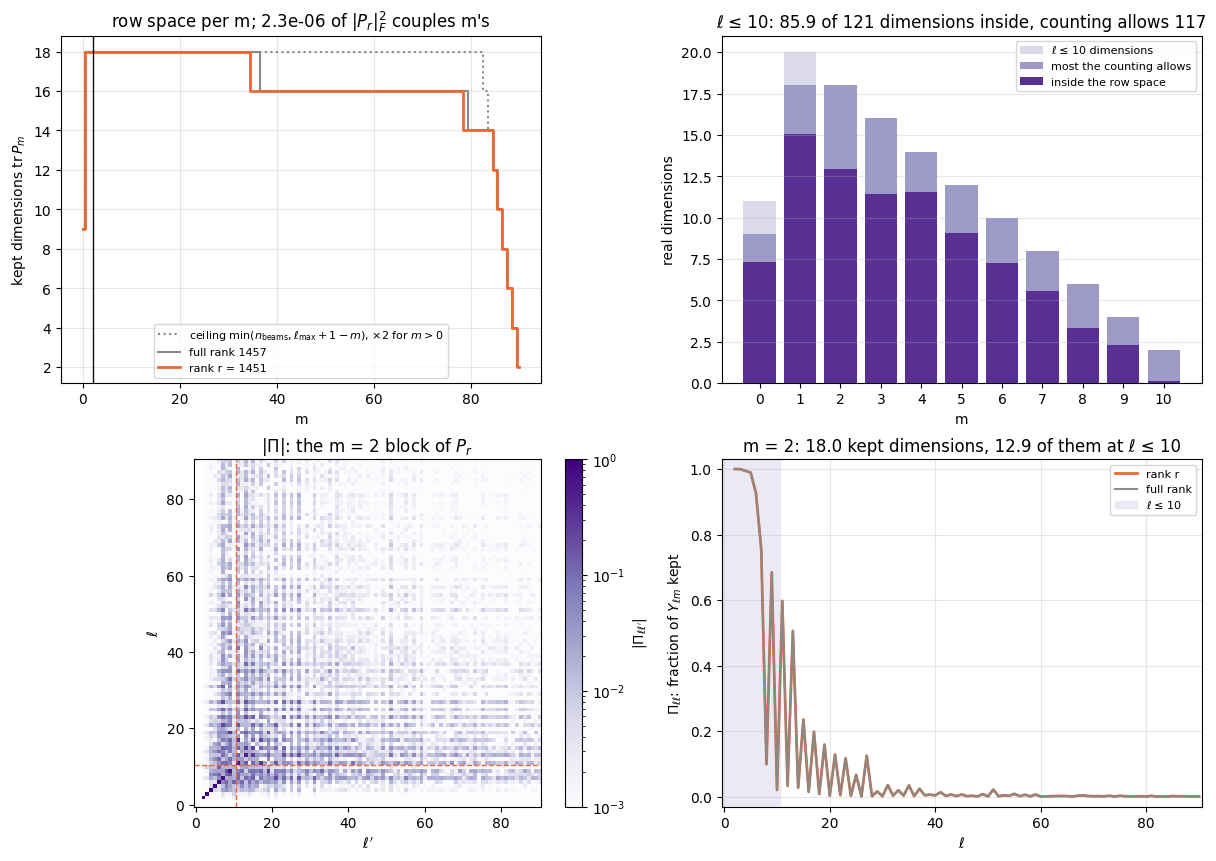

In [21]:
w_m = widgets.IntSlider(value=2, min=0, max=LMAX, description="m", **SLIDER)
ms = np.arange(L1)
m_low = np.arange(L_REP + 1)
tr_full = block_traces(kp)[0]

with plt.ioff():
    fig_mb, ((ax_mk, ax_ml), (ax_ll, ax_ld)) = plt.subplots(
        2, 2, figsize=(12, 8.5), constrained_layout=True
    )
fig_mb.canvas.header_visible = False

ax_mk.step(
    ms,
    m_ceiling,
    where="mid",
    color=C_MUTED,
    ls=":",
    lw=1.5,
    label=r"ceiling $\min(n_{\rm beams}, \ell_{\max}+1-m)$, ×2 for $m > 0$",
)
ax_mk.step(
    ms, tr_full, where="mid", color=C_MUTED, lw=1.5, label=f"full rank {kp}"
)
(line_mk,) = ax_mk.step(ms, tr_full, where="mid", color=C_PINV, lw=2)
mline_mk = ax_mk.axvline(0, color=C_TRUE, lw=1)
ax_mk.set(xlabel="m", ylabel=r"kept dimensions $\mathrm{tr}\,P_m$")
ax_mk.grid(alpha=0.3)

bars_ml = {
    key: ax_ml.bar(
        m_low, low_dim[m_low], color=plt.cm.Purples(shade), label=label
    )
    for key, shade, label in [
        ("dim", 0.25, f"ℓ ≤ {L_REP} dimensions"),
        ("cap", 0.5, "most the counting allows"),
        ("in", 0.85, "inside the row space"),
    ]
}
ax_ml.set(xlabel="m", ylabel="real dimensions", xticks=m_low)
ax_ml.legend(fontsize=8)
ax_ml.grid(alpha=0.3, axis="y")

im_ll = ax_ll.imshow(
    np.ones((L1, L1)),
    origin="lower",
    cmap="Purples",
    norm=mcolors.LogNorm(1e-3, 1, clip=True),
    interpolation="nearest",
)
fig_mb.colorbar(im_ll, ax=ax_ll, label=r"$|\Pi_{\ell\ell'}|$")
ax_ll.axhline(L_REP + 0.5, color=C_PINV, lw=1, ls="--")
ax_ll.axvline(L_REP + 0.5, color=C_PINV, lw=1, ls="--")
ax_ll.set(xlabel=r"$\ell'$", ylabel=r"$\ell$")

(line_ld,) = ax_ld.plot(ells, ells * 0.0, color=C_PINV, lw=2, label="rank r")
(line_ld_full,) = ax_ld.plot(
    ells, ells * 0.0, color=C_MUTED, lw=1.5, label="full rank"
)
ax_ld.axvspan(
    -0.5, L_REP + 0.5, color=plt.cm.Purples(0.15), label=f"ℓ ≤ {L_REP}"
)
ax_ld.set(
    xlabel=r"$\ell$",
    ylabel=r"$\Pi_{\ell\ell}$: fraction of $Y_{\ell m}$ kept",
    xlim=(-0.5, LMAX + 0.5),
    ylim=(-0.03, 1.03),
)
ax_ld.legend(fontsize=8)
ax_ld.grid(alpha=0.3)


def update_mblock():
    r, m = w_rank.value, w_m.value
    tr_m, tr_low = block_traces(r)
    line_mk.set_ydata(tr_m)
    line_mk.set_label(f"rank r = {r}")
    mline_mk.set_xdata([m, m])
    ax_mk.legend(fontsize=8)
    ax_mk.set_title(
        f"row space per m; {off_block(r):.1e} of $|P_r|_F^2$ couples m's"
    )
    cap = np.minimum(low_dim, np.round(tr_m))[m_low]
    for key, heights in [("cap", cap), ("in", tr_low[m_low])]:
        for rect, h in zip(bars_ml[key], heights):
            rect.set_height(h)
    ax_ml.set_title(
        f"ℓ ≤ {L_REP}: {tr_low.sum():.1f} of {low_dim.sum()} dimensions"
        f" inside, counting allows {cap.sum():.0f}"
    )

    Pi = np.full((L1, L1), np.nan)
    Pi[m:, m:] = np.abs(m_block(r, m))
    im_ll.set_data(np.ma.masked_invalid(Pi))
    ax_ll.set_title(rf"$|\Pi|$: the m = {m} block of $P_r$")
    for line, rk in [(line_ld, r), (line_ld_full, kp)]:
        diag = np.full(L1, np.nan)
        diag[m:] = np.diag(m_block(rk, m)).real
        line.set_ydata(diag)
    ax_ld.set_title(
        f"m = {m}: {tr_m[m]:.1f} kept dimensions,"
        f" {tr_low[m]:.1f} of them at ℓ ≤ {L_REP}"
    )
    fig_mb.canvas.draw_idle()


err_mb = connect(update_mblock, [w_rank, w_m])
show_panel(widgets.HBox([w_rank, w_m]), fig_mb, err_mb)

### In map space: point-spread functions

$P_r$ is a linear operator on maps, so its response to a point source, the
point-spread function (PSF), describes it completely:
$(P_r x)(\hat n) = \int \mathrm{PSF}(\hat n, \hat n')\,x(\hat n')\,d\Omega'$.
Because $P_r$ is block-diagonal in $m$, it commutes with rotations about
the celestial pole, and the PSF depends only on declination. A handful of
declinations therefore shows the whole operator. The point source is a
probe of $P_r$, not a model of the sky.

The probe is a delta band-limited to $\ell \le$ `L_REP`, so the usual
low-pass keeps all of it at every declination.

* **Top:** the part of the probe inside the row space,
  $\lVert P_r \delta \rVert^2 / \lVert \delta \rVert^2$, against
  declination. The band is its range over RA, which vanishes at full rank.
  Its sky mean is the number of $\ell \le$ `L_REP` dimensions inside the
  row space divided by $($`L_REP`$+1)^2$. Dotted lines mark the site
  latitudes.
* **Bottom:** six probes at the marked declinations, spread out in RA, after
  the low-pass (left) and after $P_r$ (right), on a shared colour scale in
  equatorial coordinates. The lines are $\delta = 0, \pm 30°, \pm 60°$.

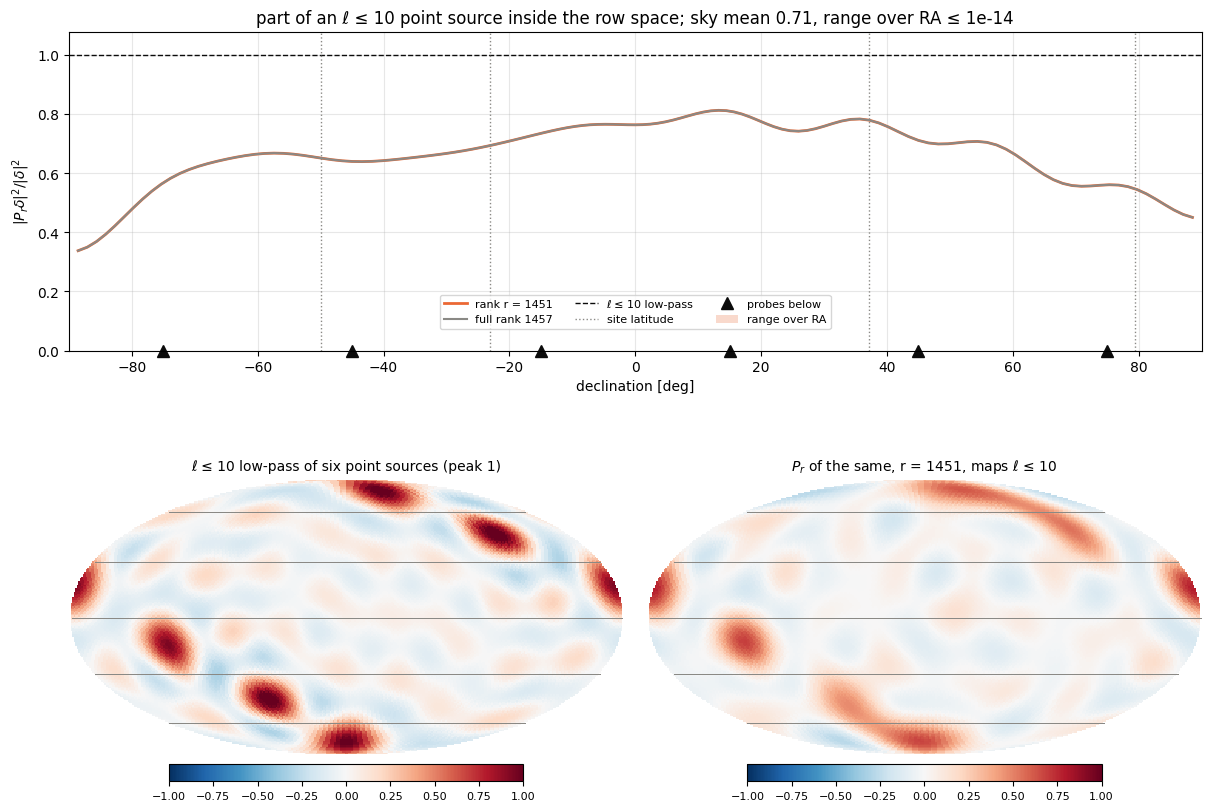

In [22]:
PSF_DECS = np.array([-75, -45, -15, 15, 45, 75])  # probe declinations [deg]
psf_ra = np.arange(PSF_DECS.size) * 360 / PSF_DECS.size  # spread out in RA
psf_pix = hp.ang2pix(NSIDE_MAP, psf_ra, PSF_DECS, lonlat=True)
# the ell <= L_REP delta at each probe: sum_ell (2 ell + 1) / 4 pi P_ell
cos_gamma = np.array(hp.pix2vec(NSIDE_MAP, psf_pix)).T @ np.array(
    hp.pix2vec(NSIDE_MAP, np.arange(NPIX))
)
delta_peak = (L_REP + 1) ** 2 / (4 * np.pi)
psf_low = (
    np.polynomial.legendre.legval(
        cos_gamma, (2 * np.arange(L_REP + 1) + 1) / (4 * np.pi)
    ).sum(axis=0)
    / delta_peak
)

with plt.ioff():
    fig_psf = plt.figure(figsize=(12, 8), constrained_layout=True)
    gs = fig_psf.add_gridspec(2, 2, height_ratios=[0.9, 1])
    ax_cov = fig_psf.add_subplot(gs[0, :])
    ax_psf = [fig_psf.add_subplot(gs[1, i]) for i in range(2)]
fig_psf.canvas.header_visible = False

(line_cov,) = ax_cov.plot(ring_dec, ring_dec * 0.0, color=C_PINV, lw=2)
(line_cov_full,) = ax_cov.plot(
    ring_dec, ring_dec * 0.0, color=C_MUTED, lw=1.5, label=f"full rank {kp}"
)
band_cov = [ax_cov.fill_between(ring_dec, 0, 0)]
ax_cov.axhline(1, color=C_TRUE, lw=1, ls="--", label=f"ℓ ≤ {L_REP} low-pass")
for i, lat in enumerate(site_lats):
    ax_cov.axvline(
        lat, color=C_MUTED, lw=1, ls=":", label=None if i else "site latitude"
    )
ax_cov.plot(
    PSF_DECS,
    np.zeros(PSF_DECS.size),
    "^",
    color=C_TRUE,
    ms=8,
    clip_on=False,
    label="probes below",
)
ax_cov.set(
    xlabel="declination [deg]",
    ylabel=r"$|P_r\delta|^2 / |\delta|^2$",
    xlim=(-90, 90),
    ylim=(0, 1.08),
)
ax_cov.grid(alpha=0.3)

im_psf = [moll_image(ax, "", "RdBu_r", moll=MOLL_EQ) for ax in ax_psf]
for ax in ax_psf:
    graticule(ax)
ax_psf[0].set_title(
    f"ℓ ≤ {L_REP} low-pass of six point sources (peak 1)", fontsize=10
)


def update_psf():
    r, sc = w_rank.value, w_scope.value
    cov = coverage(r)
    line_cov.set_ydata(ring_reduce(np.add, cov) / ring_n)
    line_cov.set_label(f"rank r = {r}")
    line_cov_full.set_ydata(ring_reduce(np.add, coverage(kp)) / ring_n)
    band_cov[0].remove()
    band_cov[0] = ax_cov.fill_between(
        ring_dec,
        ring_reduce(np.minimum, cov),
        ring_reduce(np.maximum, cov),
        color=C_PINV,
        alpha=0.25,
        lw=0,
        label="range over RA",
    )
    ax_cov.legend(
        fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.05)
    )
    ra_range = ring_reduce(np.maximum, cov) - ring_reduce(np.minimum, cov)
    ax_cov.set_title(
        f"part of an ℓ ≤ {L_REP} point source inside the row space;"
        f" sky mean {cov.mean():.2f}, range over RA ≤ {ra_range.max():.0e}"
    )
    weights = Bp["large"][:r, psf_pix].sum(axis=1)
    m_psf = weights @ Bp[sc][:r] / delta_peak
    lim = max(1.0, np.abs(m_psf).max())
    set_map(im_psf[0], psf_low, lim, symmetric=True, moll=MOLL_EQ)
    set_map(im_psf[1], m_psf, lim, symmetric=True, moll=MOLL_EQ)
    ax_psf[1].set_title(
        f"$P_r$ of the same, r = {r}, maps {SCOPE_LABEL[sc]}", fontsize=10
    )
    fig_psf.canvas.draw_idle()


err_psf = connect(update_psf, [w_rank, w_scope])
show_panel(widgets.HBox([w_rank, w_scope]), fig_psf, err_psf)

## 7c. Reporting in the row space

The maps in this notebook are shown low-passed to $\ell \le$ `PLOT_LMAX`, to
keep to the signal-dominated scales. Section 7b shows that part of that
low-pass lies in the kernel: the pseudo-inverse cannot see it, and the Wiener
filter fills it from the prior. The alternative here is to report a subspace
that the data do see and that resembles the low-pass:

* Take the principal vectors between the rank-$r$ row space and the
  $\ell \le$ `L_REP` space, from the SVD of $V_r$ restricted to
  $\ell \le$ `L_REP`. Each pair is a row-space vector $q_i$ and an
  $\ell \le$ `L_REP` vector $w_i$ at angle $\theta_i$.
* Keep the $q_i$ with $\cos\theta_i > \tau$. They span $Q$, and the
  orthogonal projection onto $Q$ is applied to the truth and the estimates
  alike.

$Q$ lies inside the row space, so $Q x^+_r - Q x_{\rm true}$ is noise only
(plus model error if `DATA_LMAX > LMAX`), with known covariance
$\beta\, G_Q^{\mathsf T} \Sigma_r^{-2} G_Q$ in the $q_i$ basis, where the
columns of $G_Q$ are the $q_i$ in the basis of $V_r$. It has no prior and no
truncation bias. The Wiener residual in $Q$ shows the Wiener
bias on the same subspace. The $q_i$ are not pure $\ell \le$ `L_REP`: they
carry the high-$\ell$ tails of the beams' constraints, so the $Q$ maps are
drawn at full $\ell$.

$Q$ depends on $r$, and so on $N$, as well as on the beams and the
frequency. Results from different configurations are only comparable
through a common $Q$.

**Top:** the truth after the low-pass, after $Q$, and the difference, which
is the cost of the substitution. **Bottom:** the two residuals in $Q$ on a
shared scale, and the pseudo-inverse noise std. The table checks the
pseudo-inverse residual against its covariance: $\chi^2 / \dim Q \approx 1$,
within $\pm\sqrt{2 / \dim Q}$. Near full rank $Q$ takes in some of the
noisiest modes of the row space, so compare with `r_picard`.

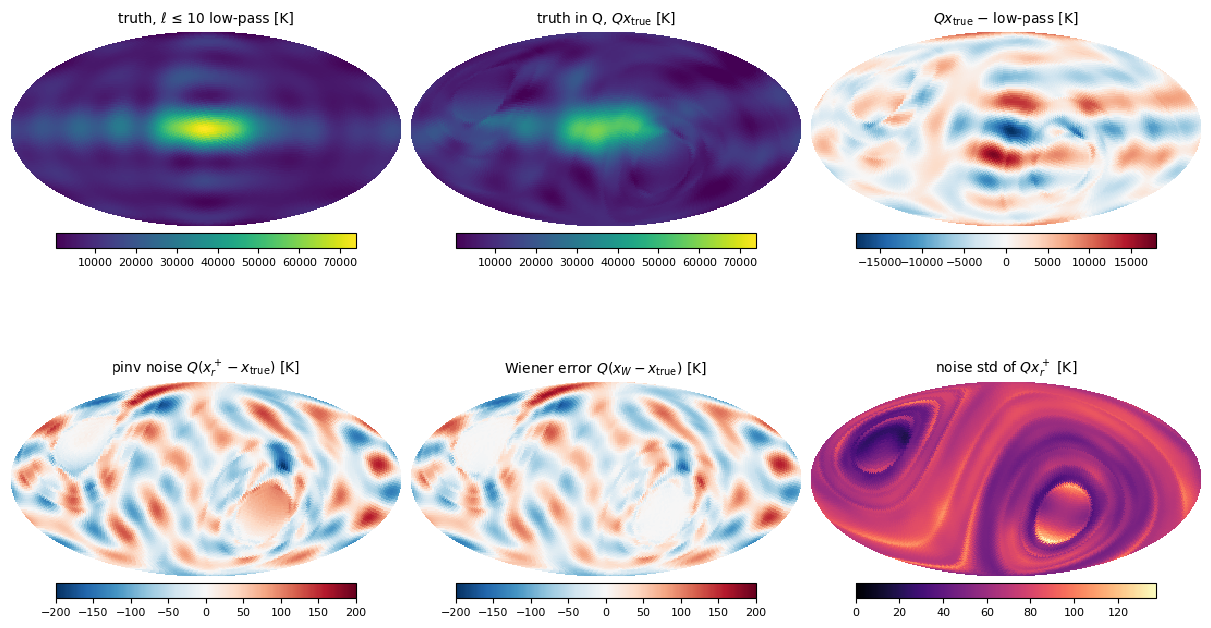

,sky RMS error in Q,expected noise RMS,χ² / dim Q (noise only: 1)
pseudo-inverse,58 K,68.8 K,0.660 ± 0.166
Wiener,52.1 K,,


In [23]:
w_tau = widgets.FloatSlider(
    value=0.9,
    min=0.0,
    max=0.99,
    step=0.01,
    description="cos θ >",
    readout_format=".2f",
    **SLIDER,
)


@lru_cache(maxsize=8)
def q_maps(r, tau):
    """Maps at full ell of the orthonormal basis q_i of Q."""
    return q_basis(r, tau).T @ Bp["full"][:r]


with plt.ioff():
    fig_q = plt.figure(figsize=(12, 7), constrained_layout=True)
    ax_qm = [fig_q.add_subplot(2, 3, i + 1) for i in range(6)]
fig_q.canvas.header_visible = False
noise_label = "noise" if DATA_LMAX == LMAX else "noise + model error"
titles = [
    f"truth, ℓ ≤ {L_REP} low-pass [K]",
    "truth in Q, $Q x_{\\rm true}$ [K]",
    "$Q x_{\\rm true}$ − low-pass [K]",
    f"pinv {noise_label} $Q(x^+_r - x_{{\\rm true}})$ [K]",
    "Wiener error $Q(x_W - x_{\\rm true})$ [K]",
    "noise std of $Q x^+_r$ [K]",
]
cmaps = ["viridis", "viridis", "RdBu_r", "RdBu_r", "RdBu_r", "magma"]
im_q = [moll_image(ax, t, cm) for ax, t, cm in zip(ax_qm, titles, cmaps)]
info_q = widgets.HTML()


def update_q():
    la, lb, r, tau = w_alpha.value, w_beta.value, w_rank.value, w_tau.value
    b = 10.0**lb
    cos = principal(r)[0]
    Gq, qm = q_basis(r, tau), q_maps(r, tau)
    a_true = Gq.T @ t_p[:r]  # coefficients of Q x_true in the q_i basis
    a_p = Gq.T @ pinv_coef(lb)[:r]
    a_w = Gq.T @ (Vtp[:r] @ wiener(la, lb)["x"])
    C = b * (Gq.T / sp[:r] ** 2) @ Gq  # noise covariance of a_p

    m_low, m_q = truth_map["large"], a_true @ qm
    std = np.sqrt(np.clip(np.einsum("ip,ip->p", C @ qm, qm), 0, None))
    lim = (m_low.min(), m_low.max())
    set_map(im_q[0], m_low, lim)
    set_map(im_q[1], m_q, lim)
    set_map(im_q[2], m_q - m_low, symmetric=True)
    d_p, d_w = a_p - a_true, a_w - a_true
    res = [d_p @ qm, d_w @ qm]
    res_lim = np.max(np.abs(np.concatenate(res)))
    set_map(im_q[3], res[0], res_lim, symmetric=True)
    set_map(im_q[4], res[1], res_lim, symmetric=True)
    set_map(im_q[5], std, (0, std.max()))

    x_low = x_true * in_low
    x_q = (Gq @ a_true) @ Vtp[:r]
    n_q = Gq.shape[1]
    dof = max(n_q, 1)
    chi2_p = d_p @ np.linalg.solve(C, d_p)
    col_rms, col_exp, col_chi = (
        "sky RMS error in Q",
        "expected noise RMS",
        "χ² / dim Q (noise only: 1)",
    )
    info_q.value = (
        f"<b>r = {r}, cos θ > {tau:.2f}</b>: dim Q = {n_q}, holding"
        f" {np.sum(cos[cos > tau] ** 2):.1f} of the {in_low.sum()}"
        f" ℓ ≤ {L_REP} dimensions. |Q x − low-pass| / |low-pass| ="
        f" {np.linalg.norm(x_q - x_low) / np.linalg.norm(x_low):.3f}<br>"
        + html_table(
            {
                "pseudo-inverse": {
                    col_rms: f"{rms(d_p @ d_p):.3g} K",
                    col_exp: f"{rms(np.trace(C)):.3g} K",
                    col_chi: f"{chi2_p / dof:.3f} ± {np.sqrt(2 / dof):.3f}",
                },
                "Wiener": {
                    col_rms: f"{rms(d_w @ d_w):.3g} K",
                    col_exp: "",
                    col_chi: "",
                },
            }
        )
    )
    fig_q.canvas.draw_idle()


err_q = connect(update_q, [w_alpha, w_beta, w_rank, w_tau])
show_panel(
    widgets.HBox([w_rank, w_tau]),
    widgets.HBox([w_alpha, w_beta]),
    fig_q,
    info_q,
    err_q,
)

## 7d. What the row space and the kernel look like

For the $\ell$ cut the basis is familiar: $Y_{\ell m}$ is a Legendre profile
in declination times $\cos m\alpha$ or $\sin m\alpha$ in RA. This section
draws the same kind of picture for the row space.

**The weights: what one beam measures at order $m$.** Write the sky and the
beam as sums of RA harmonics, $T(\alpha, \delta) = \sum_m T_m(\delta)\,
e^{im\alpha}$ and $B(\alpha, \delta) = \sum_m b_m(\delta)\, e^{im\alpha}$,
both in equatorial coordinates. As the sky turns under the beam, the
component of the timestream at frequency $m$ ($m$ cycles per sidereal
day) is

$$c_m = 2\pi \int b_m^*(\delta)\, T_m(\delta) \cos\delta\, d\delta,$$

a single weighted average over declination of the sky's $m$-th RA harmonic.
The weight $b_m(\delta)$ is the beam's own $m$-th RA harmonic. At $m = 0$ it
is how much each declination contributes to the beam's day-averaged
temperature. At $m > 0$ it is how strongly the beam responds, at each
declination, to a pattern that varies as $\cos m\alpha$. So at each $m$ the
data are $n_{\rm beams}$ numbers, one per weight, and the row space at order
$m$ is spanned by the $n_{\rm beams}$ weights.

**$\cos\theta$: how much of a pattern the data see.** Take a sky pattern $w$
of unit norm. $\cos^2\theta = \lVert P_r w \rVert^2$ is the fraction of it
inside the row space, where $\theta$ is the angle between $w$ and the row
space.
* $\cos\theta = 1$: the data measure all of $w$, and the pseudo-inverse
  recovers it up to noise.
* $\cos\theta = 0$: $w$ is in the kernel. Adding it to the sky does not
  change the data at all.

At full rank this has a direct reading: $\cos^2\theta$ is the fraction of
$w$'s declination profile that the best linear combination of the
$n_{\rm beams}$ weights at its $m$ can reproduce.

**The patterns.** At each $m$, the $\ell \le$ `L_REP` part of the sky is
spanned by $Y_{\ell m}$, $\ell = m, \dots,$ `L_REP`: the part the low-pass
keeps. The panels use a different basis of the same space, the eigenvectors
of the $\ell \le$ `L_REP` part of the $m$-block of $P_r$. Their eigenvalues
are $\cos^2\theta$, so the basis separates, as cleanly as possible, what the
data see from what is in the kernel. At each $m$ the $\cos^2\theta$ add up to
the dark bar of that $m$ in 7b.

* **Top left:** $\cos\theta$ of every $\ell \le$ `L_REP` pattern, one dot
  each at its $m$. For $m > 0$ the patterns come in cos/sin pairs, whose dots
  overlap.
* **Top middle:** the $n_{\rm beams}$ weights at the chosen $m$ against
  declination, peak-normalized: $b_m(\delta)$ at $m = 0$, and its magnitude
  $|b_m(\delta)|$ for $m > 0$, where the weight is complex. Dotted lines mark
  the site latitudes.
* **Top right:** the declination profiles of the patterns at that $m$,
  coloured by $\cos\theta$. Signed at $m = 0$; for $m > 0$ the envelope,
  one curve per cos/sin pair.
* **Bottom:** maps of the best-seen, the median and the least-seen pattern at
  that $m$, in equatorial coordinates, with lines at $\delta = 0, \pm 30°,
  \pm 60°$.

Things to look for: a pattern is seen when its declination profile can be
built from the weights. With the nominal settings, $m = 0$ has 11 patterns
($\ell = 0, \dots, 10$) but only 9 weights, so at least two patterns are
unseen whatever the beams.

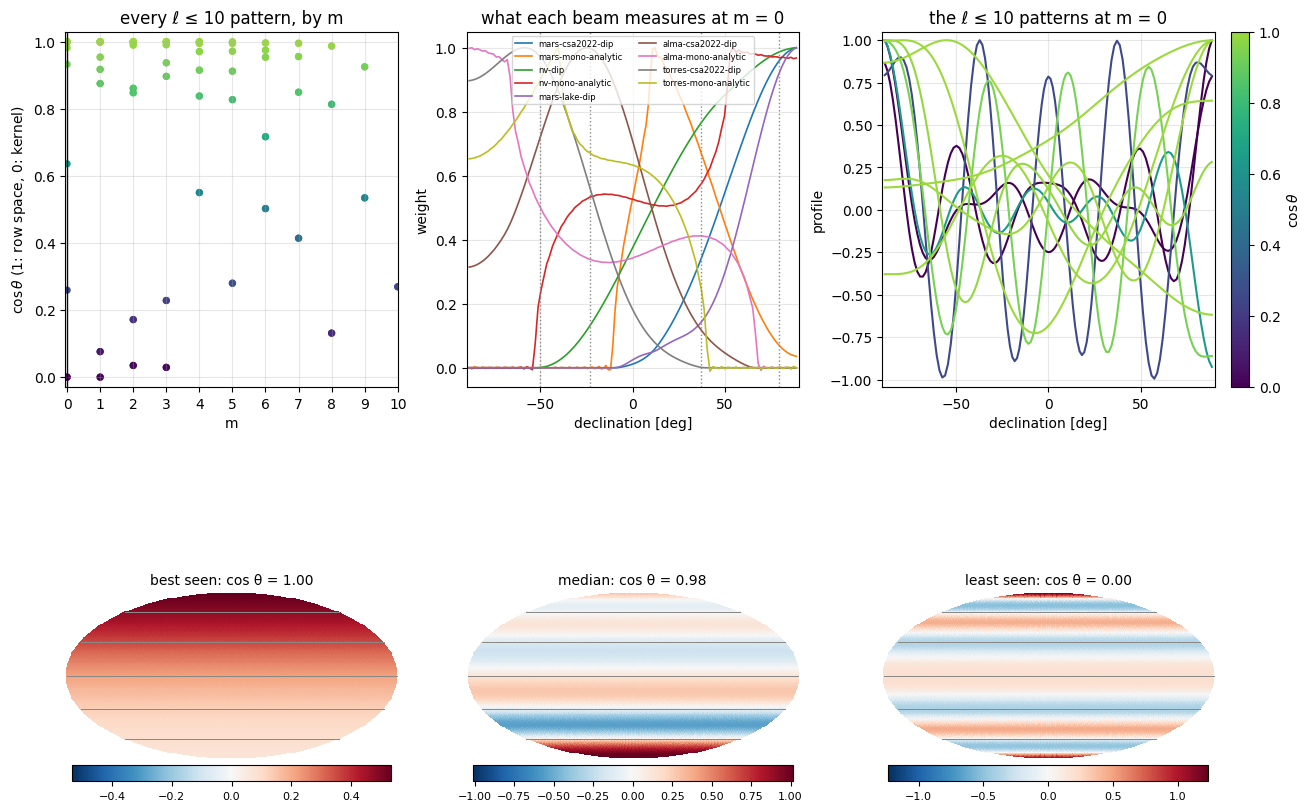

In [24]:
w_m_low = widgets.IntSlider(
    value=0, min=0, max=L_REP, description="m", **SLIDER
)
VIS = mcolors.ListedColormap(plt.cm.viridis(np.linspace(0, 0.85, 256)))
beam_colors = plt.cm.tab10(np.arange(n_beams) % 10)
n_low = in_low.sum()

with plt.ioff():
    fig_dir = plt.figure(figsize=(13, 8), constrained_layout=True)
    gs = fig_dir.add_gridspec(2, 3, height_ratios=[1, 0.9])
    ax_vis, ax_bp, ax_dp = (fig_dir.add_subplot(gs[0, i]) for i in range(3))
    ax_dm = [fig_dir.add_subplot(gs[1, i]) for i in range(3)]
fig_dir.canvas.header_visible = False

vis_pts = ax_vis.scatter(
    np.zeros(n_low),
    np.zeros(n_low),
    c=np.zeros(n_low),
    cmap=VIS,
    vmin=0,
    vmax=1,
    s=18,
)
mline_vis = ax_vis.axvline(0, color=C_TRUE, lw=1)
ax_vis.set(
    xlabel="m",
    ylabel=r"$\cos\theta$ (1: row space, 0: kernel)",
    xticks=m_low,
    ylim=(-0.03, 1.03),
    title=f"every ℓ ≤ {L_REP} pattern, by m",
)
ax_vis.grid(alpha=0.3)
fig_dir.colorbar(vis_pts, ax=ax_dp, label=r"$\cos\theta$")

lines_bp = [
    ax_bp.plot(ring_dec, ring_dec * 0.0, color=c, lw=1.2, label=name)[0]
    for name, c in zip(beam_names, beam_colors)
]
for lat in site_lats:
    ax_bp.axvline(lat, color=C_MUTED, lw=1, ls=":")
ax_bp.set(xlabel="declination [deg]", ylabel="weight", xlim=(-90, 90))
ax_bp.legend(fontsize=6, ncol=2)
ax_bp.grid(alpha=0.3)
ax_dp.set(xlabel="declination [deg]", ylabel="profile", xlim=(-90, 90))
ax_dp.grid(alpha=0.3)

im_dm = [moll_image(ax, "", "RdBu_r", moll=MOLL_EQ) for ax in ax_dm]
for ax in ax_dm:
    graticule(ax)
info_dir = widgets.HTML()


def update_dir():
    r, m = w_rank.value, w_m_low.value
    per_m = [low_directions(r, k) for k in m_low]
    cos_all = np.concatenate([c for c, _ in per_m])
    m_all = np.repeat(m_low, [c.size for c, _ in per_m])
    vis_pts.set_offsets(np.column_stack([m_all, cos_all]))
    vis_pts.set_array(cos_all)
    mline_vis.set_xdata([m, m])

    prof_b = beam_profiles(m)
    for line, p in zip(lines_bp, prof_b):
        line.set_ydata(p)
    ax_bp.set_ylim(min(0, prof_b.min()) - 0.05, 1.05)
    ax_bp.set_title(f"what each beam measures at m = {m}")

    cos, w = per_m[m]
    maps = w @ B_low[low_pos[m]]
    prof = peak_normalize(dec_profile(maps, m))
    for line in list(ax_dp.lines):
        line.remove()
    # for m > 0 the patterns come in cos/sin pairs with one envelope
    shown = np.arange(0, cos.size, 1 if m == 0 else 2)
    for i in shown[np.argsort(cos[shown])]:  # the best-seen on top
        ax_dp.plot(ring_dec, prof[i], color=VIS(cos[i]), lw=1.5)
    ax_dp.set_ylim(min(0, prof.min()) - 0.05, 1.05)
    ax_dp.set_title(
        f"the ℓ ≤ {L_REP} patterns at m = {m}"
        + ("" if m == 0 else ", one per cos/sin pair")
    )

    picks = [(0, "best seen"), (cos.size // 2, "median")]
    picks.append((cos.size - 1, "least seen"))
    for ax, im, (i, tag) in zip(ax_dm, im_dm, picks):
        set_map(im, maps[i], symmetric=True, moll=MOLL_EQ)
        ax.set_title(f"{tag}: cos θ = {cos[i]:.2f}", fontsize=10)

    tr_m = block_traces(r)[0]
    info_dir.value = (
        f"<b>r = {r}, m = {m}</b>: {cos.size} ℓ ≤ {L_REP} patterns, of"
        f" which {np.sum(cos**2):.1f} dimensions are inside the row space"
        f" and {np.sum(cos < 0.1)} patterns have cos θ < 0.1. The row space"
        f" at this m has {tr_m[m]:.1f} dimensions (ceiling {m_ceiling[m]})."
    )
    fig_dir.canvas.draw_idle()


err_dir = connect(update_dir, [w_rank, w_m_low])
show_panel(widgets.HBox([w_rank, w_m_low]), fig_dir, info_dir, err_dir)

## 8. Head to head

The same controls drive both figures.

**Maps:** the truth, $x_W$ and $x^+_r$. Below them, the two errors (on a
shared colour scale) and the difference between the two methods.

**Diagnostics:**
* Per $\ell$: the transfer function $C_\ell^{\hat x \times x}/C_\ell^{x}$ and
  the relative error power $C_\ell^{\hat x - x}/C_\ell^{x}$, for Wiener, the
  pseudo-inverse and the noiseless $P_r x_{\rm true}$.
* Against $r$: each method's error split into the part inside the row space
  $\mathrm{row}_r$ and the part in the kernel. This uses the full
  Euclidean alm norm, so the two parts add in quadrature. Inside the row
  space the comparison is fair. In the kernel the pseudo-inverse always
  misses the truth's whole kernel part, and Wiener can only do better
  through prior correlations.

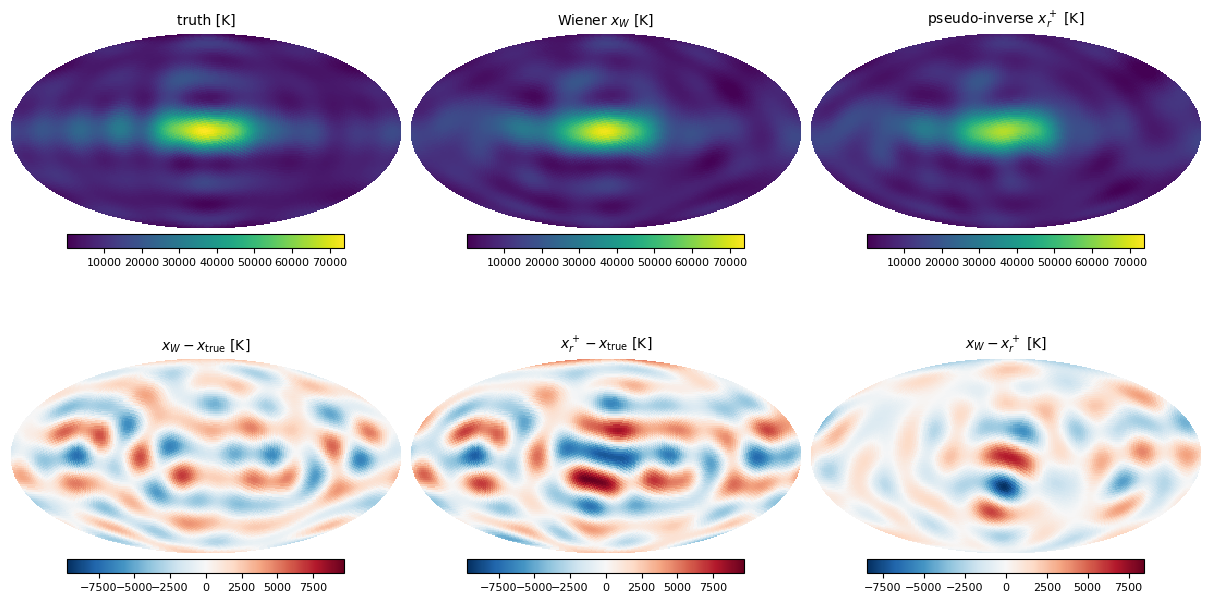

,"sky RMS error, ℓ ≤ 10",fractional map residual,row-space error,kernel error,χ² / N_data
Wiener,2.32e+03 K,0.347,1.7e+03 K,7.39e+03 K,0.8314
pseudo-inverse,2.91e+03 K,0.5,7.45e+08 K,7.87e+03 K,0.6570
noiseless $P_r x$,2.94e+03 K,0.511,4.76e-11 K,7.87e+03 K,0.9622


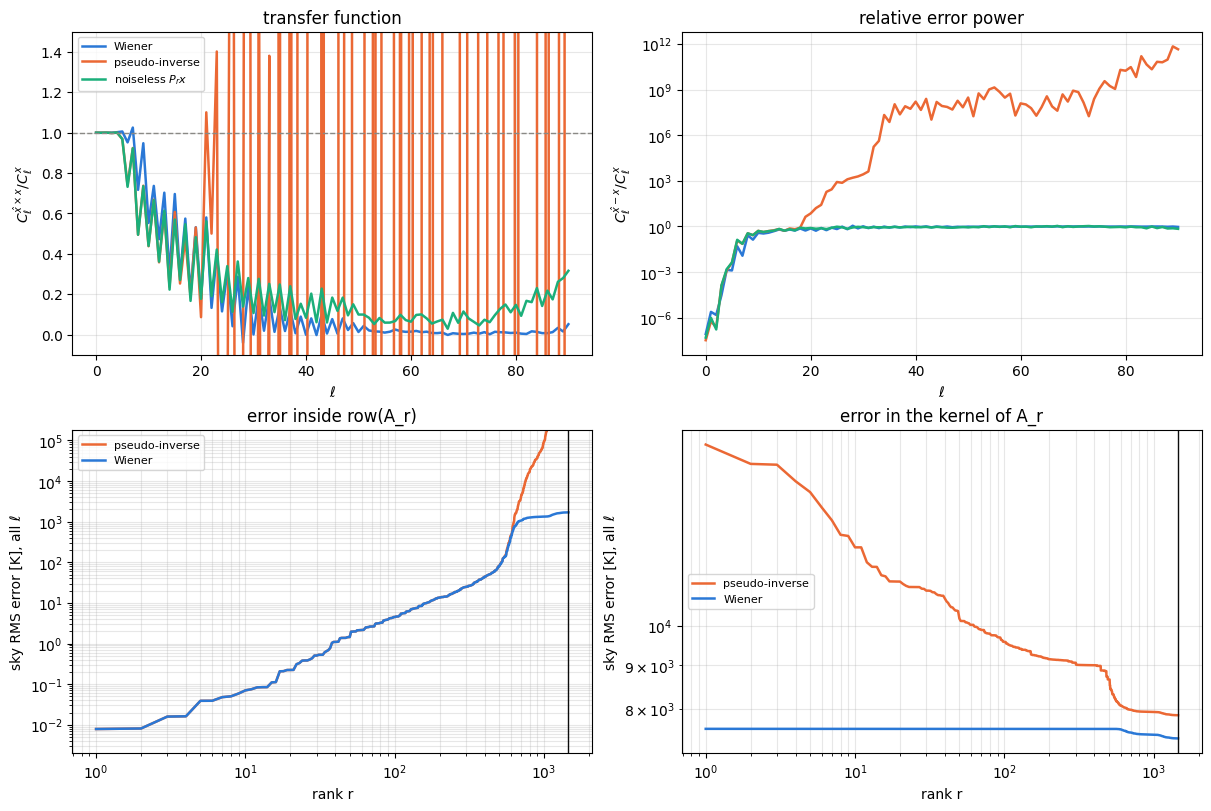

In [25]:
with plt.ioff():
    fig_h = plt.figure(figsize=(12, 6.5), constrained_layout=True)
    ax_hm = [fig_h.add_subplot(2, 3, i + 1) for i in range(6)]
fig_h.canvas.header_visible = False
titles = [
    "truth [K]",
    "Wiener $x_W$ [K]",
    "pseudo-inverse $x^+_r$ [K]",
    "$x_W - x_{\\rm true}$ [K]",
    "$x^+_r - x_{\\rm true}$ [K]",
    "$x_W - x^+_r$ [K]",
]
cmaps = ["viridis"] * 3 + ["RdBu_r"] * 3
im_h = [moll_image(ax, t, cm) for ax, t, cm in zip(ax_hm, titles, cmaps)]

with plt.ioff():
    fig_d, ((ax_tf, ax_re), (ax_row, ax_ker)) = plt.subplots(
        2, 2, figsize=(12, 8), constrained_layout=True
    )
fig_d.canvas.header_visible = False
EST = {
    "Wiener": C_WIENER,
    "pseudo-inverse": C_PINV,
    "noiseless $P_r x$": C_ROW,
}
lines_tf = {
    n: ax_tf.plot(ells, ells * 0.0, color=c, lw=1.8, label=n)[0]
    for n, c in EST.items()
}
lines_re = {
    n: ax_re.semilogy(ells, ells + 1.0, color=c, lw=1.8, label=n)[0]
    for n, c in EST.items()
}
ax_tf.axhline(1, color=C_MUTED, ls="--", lw=1)
ax_tf.set(
    xlabel=r"$\ell$",
    ylabel=r"$C_\ell^{\hat x \times x}/C_\ell^x$",
    title="transfer function",
)
ax_re.set(
    xlabel=r"$\ell$",
    ylabel=r"$C_\ell^{\hat x - x}/C_\ell^x$",
    title="relative error power",
)
ax_tf.legend(fontsize=8)
for ax in (ax_tf, ax_re):
    ax.grid(alpha=0.3)

lines_split = {}
for ax, part, title in [
    (ax_row, "row", "error inside row(A_r)"),
    (ax_ker, "ker", "error in the kernel of A_r"),
]:
    for key, name, c in [
        ("p", "pseudo-inverse", C_PINV),
        ("w", "Wiener", C_WIENER),
    ]:
        lines_split[f"{key}_{part}"] = ax.loglog(
            k_p, k_p * 1.0, color=c, lw=1.8, label=name
        )[0]
    ax.set(xlabel="rank r", ylabel="sky RMS error [K], all ℓ", title=title)
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)
rlines_split = [ax.axvline(1, color=C_TRUE, lw=1) for ax in (ax_row, ax_ker)]
info_h = widgets.HTML()


def update_h2h_maps():
    la, lb, r, sc = w_alpha.value, w_beta.value, w_rank.value, w_scope.value
    m_true = truth_map[sc]
    m_w = wiener(la, lb)["coef"] @ Bw[sc]
    m_p = pinv_coef(lb)[:r] @ Bp[sc][:r]
    lim = (m_true.min(), m_true.max())
    for im, m in zip(im_h[:3], [m_true, m_w, m_p]):
        set_map(im, m, lim)
    res_lim = np.max(np.abs(np.concatenate([m_w - m_true, m_p - m_true])))
    set_map(im_h[3], m_w - m_true, res_lim, symmetric=True)
    set_map(im_h[4], m_p - m_true, res_lim, symmetric=True)
    set_map(im_h[5], m_w - m_p, symmetric=True)
    fig_h.canvas.draw_idle()


def update_h2h_diag():
    la, lb, r, sc = w_alpha.value, w_beta.value, w_rank.value, w_scope.value
    ests = {
        "Wiener": wiener(la, lb)["x"],
        "pseudo-inverse": pinv(r, lb),
        "noiseless $P_r x$": t_p[:r] @ Vtp[:r],
    }
    cl_true = cl_packed(x_true)
    for name, x in ests.items():
        lines_tf[name].set_ydata(cl_packed(x, x_true) / cl_true)
        lines_re[name].set_ydata(cl_packed(x - x_true) / cl_true)
    for ax in (ax_tf, ax_re):
        ax.relim()
        ax.autoscale_view()
    ax_tf.set_ylim(-0.1, 1.5)
    split = split_curves(la, lb)
    for key, line in lines_split.items():
        line.set_ydata(split[key])
    for ax in (ax_row, ax_ker):
        ax.relim()
        ax.autoscale_view()
    ax_row.set_ylim(top=10 * rms(x_true @ x_true))
    for line in rlines_split:
        line.set_xdata([r, r])

    m_true = truth_map[sc]
    rows = {}
    for name, x in ests.items():
        d = (x - x_true)[SCOPES[sc]]
        m_hat = maps_of(x, sc)[0]
        dr = Vtp[:r] @ (x - x_true)
        dk = (x - x_true) - dr @ Vtp[:r]
        rows[name] = {
            f"sky RMS error, {SCOPE_LABEL[sc]}": f"{rms(d @ d):.3g} K",
            "fractional map residual": f"{frac_rms(m_hat, m_true):.3g}",
            "row-space error": f"{rms(dr @ dr):.3g} K",
            "kernel error": f"{rms(dk @ dk):.3g} K",
            "χ² / N_data": f"{chi2(x, lb) / ndata:.4f}",
        }
    info_h.value = html_table(rows)
    fig_d.canvas.draw_idle()


def update_h2h():
    update_h2h_maps()
    update_h2h_diag()


err_h = connect(update_h2h, [w_alpha, w_beta, w_rank, w_scope])
show_panel(
    widgets.HBox([w_alpha, w_beta]),
    widgets.HBox([w_rank, w_scope]),
    fig_h,
    info_h,
    fig_d,
    err_h,
)

## 9. Snapshot at the current slider settings

A static, higher-resolution comparison in the style of the other mapmaking
notebooks (`plotting.plot_comparison_grid`). The residual is fractional,
(true − rec) / true. Re-run this cell after moving the sliders.

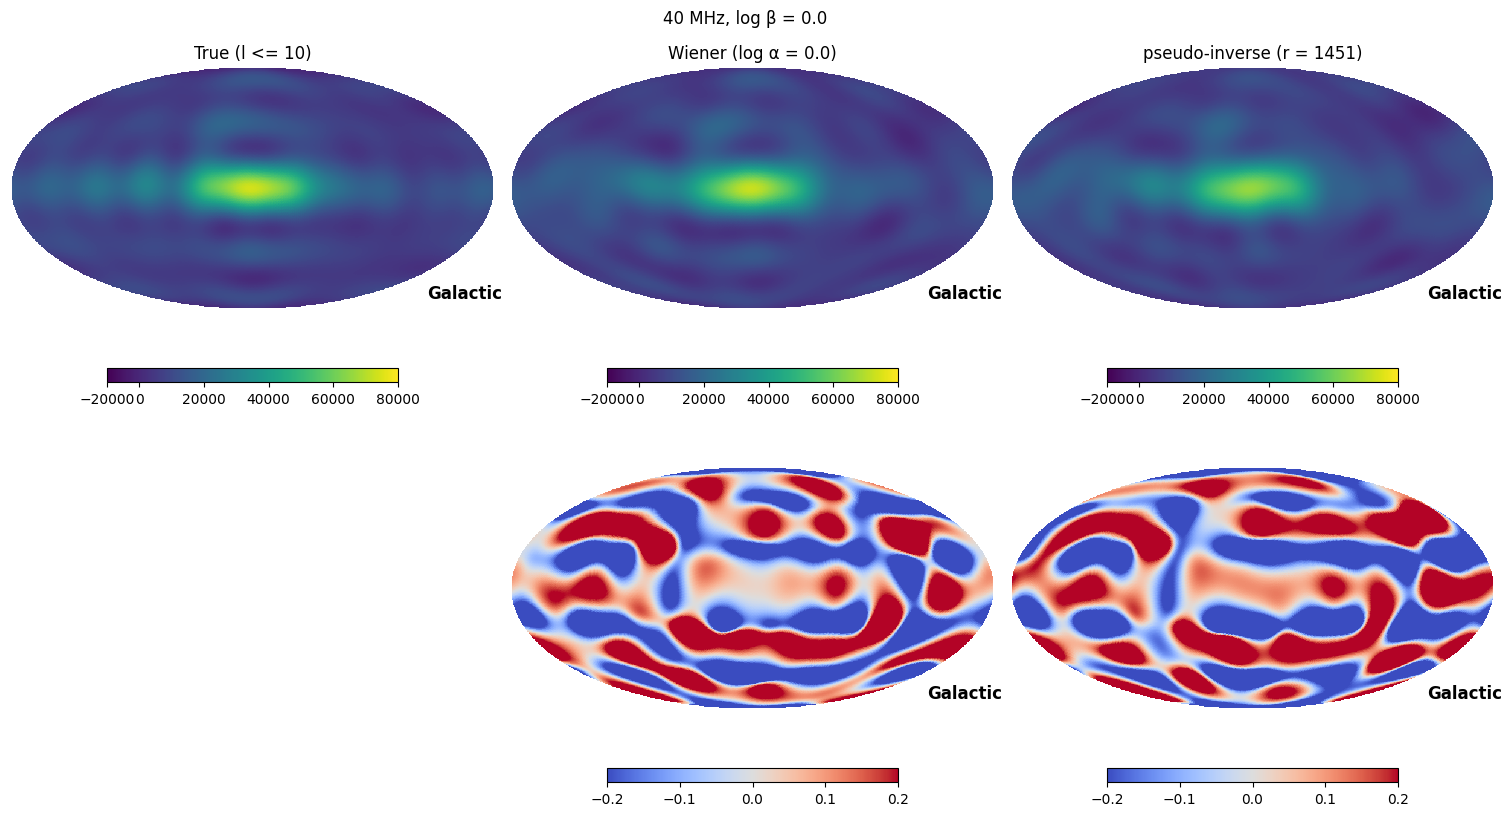

In [26]:
FRAC_RANGE = 0.2  # colour range of the fractional residual

la, lb, r = w_alpha.value, w_beta.value, w_rank.value
hp_true, hp_w, hp_p = packed_to_hp(
    np.stack([x_true, wiener(la, lb)["x"], pinv(r, lb)])
)
fig_snap = msplt.plot_comparison_grid(
    hp_true,
    [hp_w, hp_p],
    [f"Wiener (log α = {la:.1f})", f"pseudo-inverse (r = {r})"],
    lmax=LMAX,
    plot_lmax=PLOT_LMAX,
    nside=128,
    plot_galactic=GALACTIC,
    frac_range=FRAC_RANGE,
    ratio=True,
)
fig_snap.suptitle(f"{FREQ_MHZ} MHz, log β = {lb:.1f}", y=1.02)
plt.show()

## 10. Data-only comparison at the Picard rank

A static version of section 9, independent of the sliders:

* the pseudo-inverse at the data-only Picard cut `r_picard` (section 3),
  which needs no truth;
* the Wiener filter at the nominal prior and noise, $\alpha = \beta = 1$.

The same two estimates in three views:

1. full resolution, $\ell \le$ `LMAX`;
2. the usual low-pass, $\ell \le$ `PLOT_LMAX`;
3. the row space of rank `r_picard`: the truth and both estimates projected
   with $P_r$. The pseudo-inverse already lies in it, so its residual there is
   noise only (plus model error if `DATA_LMAX > LMAX`). The Wiener residual
   is its error on the modes the data measure.

Residuals are absolute, truth − estimate, in K. The band-limited truth crosses
zero at full resolution and in the row space, where a fractional residual is
undefined. At full resolution a few bright compact sources dominate the
residuals, so their colour range is set at the `RES_PERCENTILE`th percentile
of |residual| instead of the maximum.

The bottom-left panel of views 2 and 3 is what the view leaves out of the
truth: the truth minus its low-pass (all of $\ell >$ `PLOT_LMAX`), and the
truth minus its row-space part (the kernel of rank `r_picard`). It has its
own colour range, at the 99th percentile of its absolute value. Neither
estimate is scored on it.

The table gives the sky-RMS errors in each view. The pseudo-inverse noise
column is its expected noise alone, $\beta \sum_{k \le r}
\lVert v_k \rVert^2 / \sigma_k^2$ restricted to the view; the rest of its
error is truncation bias and kernel.

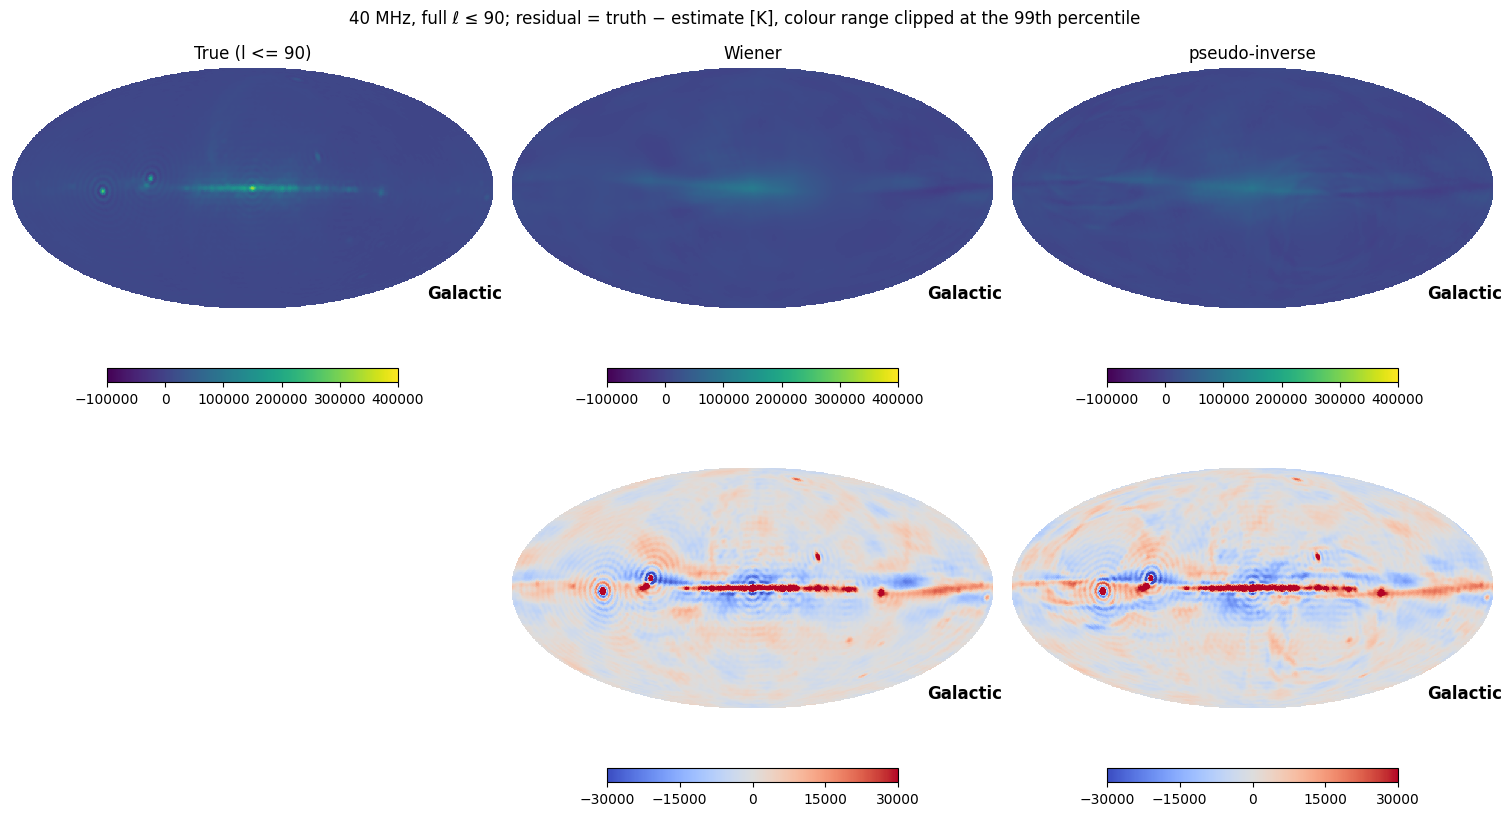

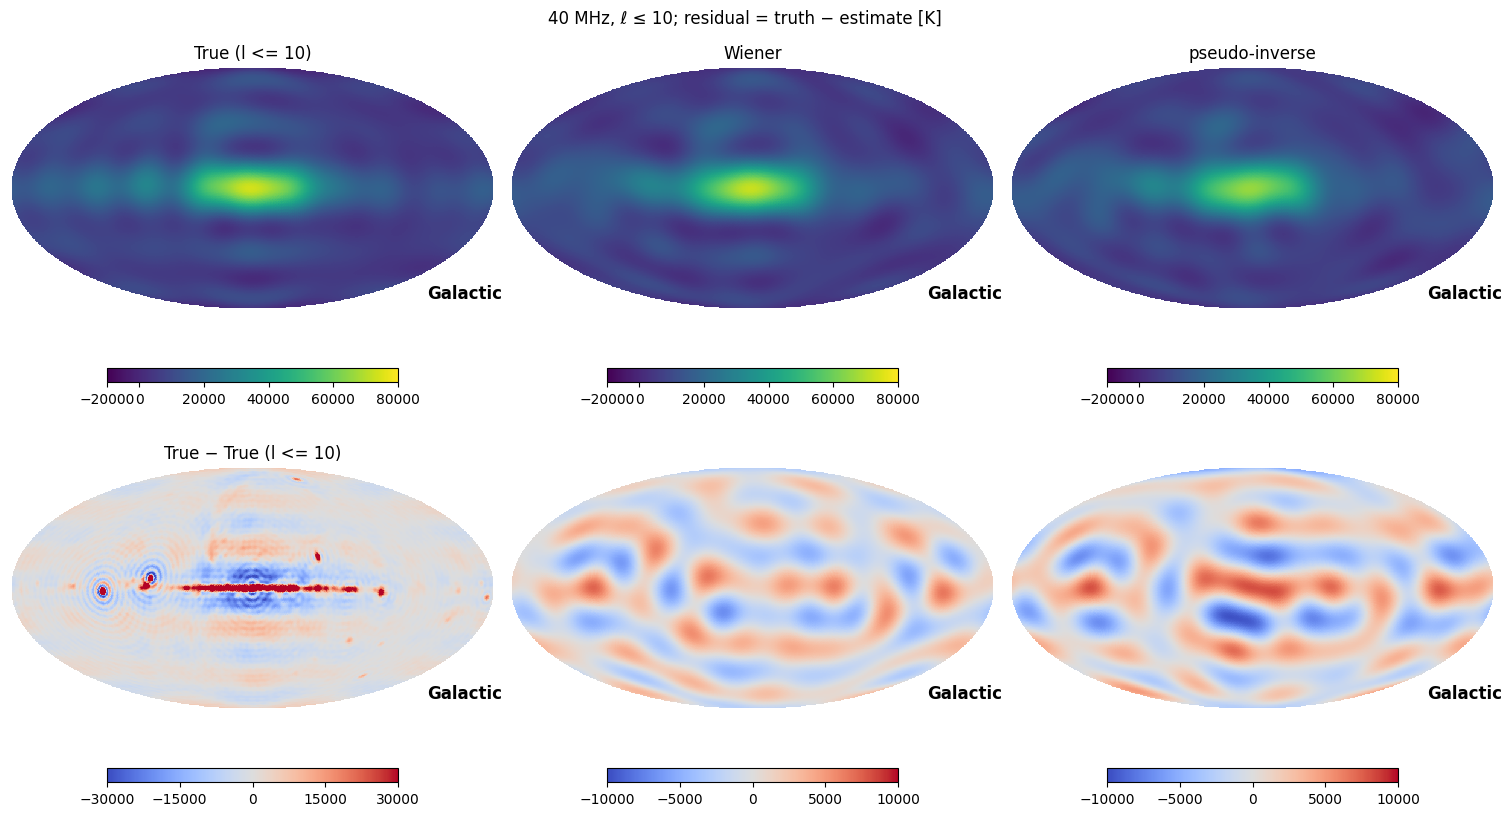

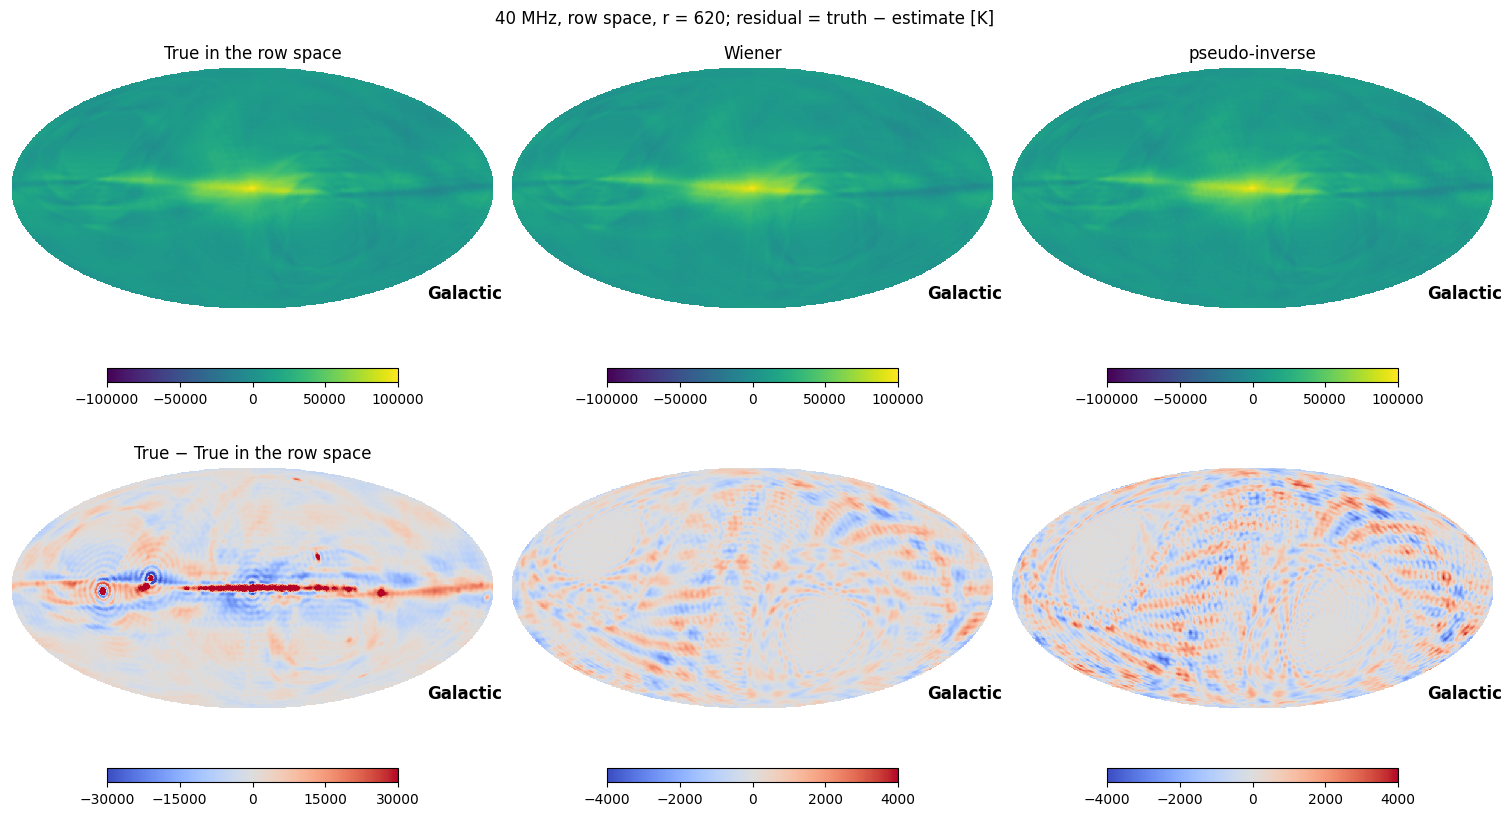

,truth RMS,Wiener error,pseudo-inverse error,pseudo-inverse noise (expected)
full ℓ ≤ 90,1.827e+04 K,7.58e+03 K,8.09e+03 K,780 K
ℓ ≤ 10,1.63e+04 K,2.32e+03 K,2.93e+03 K,93.6 K
"row space, r = 620",1.64e+04 K,609 K,817 K,780 K


In [27]:
LOG_ALPHA_REP, LOG_BETA_REP = 0.0, 0.0  # nominal prior and noise
r_rep = r_picard  # the data-only rank: no truth needed
x_w_rep = wiener(LOG_ALPHA_REP, LOG_BETA_REP)["x"]
x_p_rep = pinv(r_rep, LOG_BETA_REP)
V_rep = Vtp[:r_rep]


def to_row(x):
    """P_r x: the part of x in the row space of rank r_rep."""
    return (V_rep @ x) @ V_rep


RES_PERCENTILE = 99  # colour range of the full-resolution residuals

# name: (low-pass for the plot, projection, title of the true map, title of
# the panel of what the view leaves out of the truth, residual percentile)
views = {
    f"full ℓ ≤ {LMAX}": (LMAX, lambda x: x, None, None, RES_PERCENTILE),
    f"ℓ ≤ {PLOT_LMAX}": (
        PLOT_LMAX,
        lambda x: x * SCOPES["large"],
        None,
        f"True − True (l <= {PLOT_LMAX})",
        None,
    ),
    f"row space, r = {r_rep}": (
        LMAX,
        to_row,
        "True in the row space",
        "True − True in the row space",
        None,
    ),
}
noise_sq = 10.0**LOG_BETA_REP * np.sum(V_rep**2 / sp[:r_rep, None] ** 2, 0)
labels_rep = ["Wiener", "pseudo-inverse"]

rows = {}
figs_rep = {}
for view, (plot_lmax, proj, true_label, left_out, pct) in views.items():
    xs = [proj(x) for x in (x_true, x_w_rep, x_p_rep)]
    hp_true, hp_w, hp_p = packed_to_hp(np.stack(xs))
    hp_left_out = None if left_out is None else packed_to_hp(x_true - xs[0])[0]
    figs_rep[view] = msplt.plot_comparison_grid(
        hp_true,
        [hp_w, hp_p],
        labels_rep,
        lmax=LMAX,
        plot_lmax=plot_lmax,
        nside=128,
        plot_galactic=GALACTIC,
        ratio=False,
        true_label=true_label,
        res_percentile=pct,
        x_removed=hp_left_out,
        removed_label=left_out,
    )
    clip = (
        ""
        if pct is None
        else f", colour range clipped at the {pct}th percentile"
    )
    figs_rep[view].suptitle(
        f"{FREQ_MHZ} MHz, {view}; residual = truth − estimate [K]{clip}",
        y=1.02,
    )
    plt.show()
    d_w, d_p = xs[1] - xs[0], xs[2] - xs[0]
    sel = SCOPES["large"] if plot_lmax == PLOT_LMAX else SCOPES["full"]
    rows[view] = {
        "truth RMS": f"{rms(xs[0] @ xs[0]):.4g} K",
        "Wiener error": f"{rms(d_w @ d_w):.3g} K",
        "pseudo-inverse error": f"{rms(d_p @ d_p):.3g} K",
        "pseudo-inverse noise (expected)": f"{rms(noise_sq[sel].sum()):.3g} K",
    }
display(HTML(html_table(rows)))

### Angular power spectra

$C_\ell$ of the truth and of the two estimates of section 10, at full
resolution. Two reference curves:

* the truth in the row space, $P_r x_{\rm true}$: the most any rank-$r$
  pseudo-inverse can recover;
* the expected noise spectrum of the pseudo-inverse,
  $N_\ell = \beta \sum_{k \le r} \lVert [v_k]_\ell \rVert^2 / \sigma_k^2 /
  (2\ell + 1)$.

The pseudo-inverse spectrum is roughly the sum of the two. The Wiener
spectrum falls below the truth where the prior dominates. The bottom panel is
each spectrum divided by the truth's. The dashed line marks `PLOT_LMAX`.

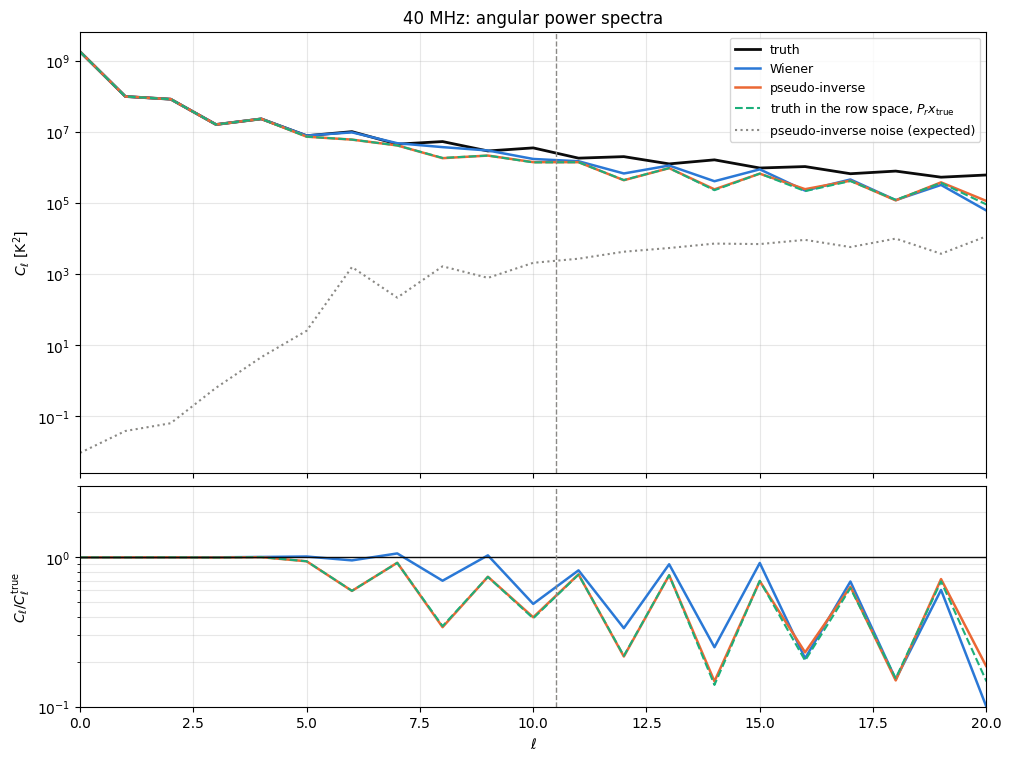

In [30]:
cl_true = cl_packed(x_true)
noise_cl = np.bincount(ell_p, noise_sq, minlength=L1) / (2 * ells + 1)
spectra = [
    ("Wiener", cl_packed(x_w_rep), C_WIENER, "-", 1.8),
    ("pseudo-inverse", cl_packed(x_p_rep), C_PINV, "-", 1.8),
    (
        "truth in the row space, $P_r x_{\\rm true}$",
        cl_packed(to_row(x_true)),
        C_ROW,
        "--",
        1.5,
    ),
    ("pseudo-inverse noise (expected)", noise_cl, C_MUTED, ":", 1.5),
]

fig_cl, (ax_cl, ax_rat) = plt.subplots(
    2,
    1,
    figsize=(10, 7.5),
    sharex=True,
    height_ratios=[2, 1],
    constrained_layout=True,
)
ax_cl.semilogy(ells, cl_true, color=C_TRUE, lw=2, label="truth")
for name, cl, c, ls, lw in spectra:
    ax_cl.semilogy(ells, cl, color=c, ls=ls, lw=lw, label=name)
    ax_rat.semilogy(ells, cl / cl_true, color=c, ls=ls, lw=lw)
ax_rat.axhline(1, color=C_TRUE, lw=1)
for ax in (ax_cl, ax_rat):
    ax.axvline(PLOT_LMAX + 0.5, color=C_MUTED, lw=1, ls="--")
    ax.grid(alpha=0.3, which="both")
ax_cl.set(
    ylabel=r"$C_\ell$ [K$^2$]",
    title=f"{FREQ_MHZ} MHz: angular power spectra",
)
ax_cl.legend(fontsize=9)
ax_rat.set(
    xlabel=r"$\ell$",
    ylabel=r"$C_\ell / C_\ell^{\rm true}$",
    xlim=(0, 20),
    ylim=(1e-1, 3),
)
plt.show()

## Notes

* **Cost.** $A$ is $1629 \times 8281$ (0.11 GB) for the nine nominal beams
  at the Nyquist $2\ell_{\max}+1 = 181$ samples per beam ($3231 \times
  8281$ with `DATA_LMAX = 179`).
  The first run takes several minutes: a few for the beam transforms, about
  one per exact SVD, and a little more for the stacked-beam spectra. All of
  it is cached. After that, a slider update is a handful of matrix-vector
  products. The rank is at most
  $\sum_m \min(n_{\rm beams}, \ell_{\max}+1-|m|) = 1557$ (section 3), a
  little below $n_{\rm beams}(2\ell_{\max}+1) = 1629$. The remaining
  $\gtrsim 6700$
  dimensions of the $\ell_{\max} = 90$ alm space are kernel however long the
  noise is integrated down.
* **The kernel depends on the metric.** "The row space of $A$" means the
  Euclidean (packed-alm, i.e. map-$L_2$) complement of the kernel. The
  Wiener filter at large $\alpha$ is the pseudo-inverse in the $S^{-1}$
  metric instead. The two differ in the kernel vector they pick, not in
  what the data constrain.
* **The oracle rank uses the truth.** A prior-free choice has to come from
  the data, for example the Picard plot, a discrepancy principle
  ($\chi^2/N \approx 1$) or cross-validation between beams.
* **Model error.** With `DATA_LMAX = 179` the unmodelled $\ell > 90$ sky
  enters the data coefficients (Picard plot). The pseudo-inverse amplifies
  it by $1/\sigma_k$; the Wiener filter damps it together with the noise.